# 쓰레기 이미지 12종 분류 — 데이터 전처리부터 최종 모델 학습·평가까지

**목표**: 쓰레기 사진을 12개 클래스(battery, biological, brown-glass, cardboard, clothes, green-glass, metal, paper, plastic, shoes, trash, white-glass)로 분류한다. 평가 지표는 Accuracy다.

**모델**: ResNet 구조를 참고해 `torch.nn`으로 직접 설계한 작은 CNN. **사전학습 없이 처음부터 학습**한다.
- 사전학습 가중치와 `torchvision.models`는 쓰지 않는다. torchvision은 이미지 변환(transforms)에만 쓴다.
- 하이퍼파라미터는 한 번에 하나씩 바꾸는 실험 사다리로 정했다. 사다리는 두 차례 돌린다.
  - **1차(R1~R12)**: 정리 전 데이터(학습 12,000장)로 진행했고 최고는 R9(val_avg 0.502; val 0.816 / val_ext 0.184 / val_hard 0.506)였다. 외부 데이터를 섞으면(R2) val_ext가 0.144에서 0.772로 올랐지만, 당시 채택 조건(clothes·shoes 유지)에 걸려 기각했다.
  - **그 사이에 데이터를 정리했다**: 사진을 직접 확인해 라벨과 맞지 않는 사진을 걸러내고 외부 데이터를 더 모았다. 학습 27,050장 / val_ext 498장 / test_ext 360장 / val_hard 1,198장이 되었다 (3절).
  - **2차(M1~M9)**: 정리한 데이터로 채택 조건을 바꿔(clothes·shoes 조건 제거, val_avg +0.01 이상만 채택) 다시 돌린다. 비율을 유지하는 전처리(letterbox), 증강(좌우·상하 반전, 회전, 색상, TrivialAugmentWide, 어둡게·흐림), 클래스 가중치를 비교하고, 배경만 보고 맞히는지 확인하는 지표도 함께 본다. 무작위 자르기는 쓰지 않는다.
  - **2차 결과**: M1(정리한 데이터) → M3(반전·회전 증강) → M8(epoch 60) 순으로 채택되어 **최종 설정은 M8** (val_avg 0.877; val 0.879 / val_ext 0.922 / val_hard 0.830). 해석은 10절 끝에 있다.

| 절 | 내용 |
|---|---|
| 1 | 환경·경로·실행 스위치 |
| 2 | 원본 데이터(Kaggle) 분할 70/15/15 |
| 3 | 외부 데이터 통합(V2·RealWaste·AI Hub·TrashBusters 등)·중복 제거·사진 확인 정리 → 학습 데이터와 외부 검증셋 |
| 4 | 손상 검증셋 생성 (흐림·어둡게·빛번짐) |
| 5 | 외부 테스트셋 생성 |
| 6 | 이미지 캐시·전처리·증강 |
| 7 | 모델 정의 (직접 구현한 작은 ResNet) |
| 8 | 학습 함수와 실험 실행기 |
| 9 | 실험 사다리 — 하이퍼파라미터 튜닝 (1차 R1~R12, 2차 M1~M9) |
| 10 | 튜닝 과정 시각화 (epoch 증가 효과 포함) |
| 11 | 최종 모델 검증 평가 (val / val_ext / val_hard / val_avg) |
| 12 | 최종 TEST (1회) |
| 13 | 결론 |

**실행 안내**
- **Google Colab**: 노트북만 열고 위에서부터 실행하면 된다. 1절이 Google Drive 공개 폴더 `garbage_classification`에서 데이터 zip·분할 CSV·최종 모델 가중치를 내려받아 `/content/garbage_classification`에 푼다.
  - 내 Drive에 같은 폴더가 있으면 그것을 쓰고, 없으면 공개 링크로 내려받는다.
  - Drive 폴더: https://drive.google.com/drive/folders/19R4yPCNI2B204UuINfGlBx4IZ7N2j9XB
- **로컬**: 저장소의 `01_coding/notebooks/` 폴더에서 열고 실행한다.
- AI Hub 사진(`aihub_recycling.zip`, `aihub_extra.zip`)은 이용약관(재배포 금지) 때문에 비공개다. 공개 폴더의 zip 중 `extra_public.zip`(07_extra_external)은 2차에서 추가한 공개 외부 사진이다.
- AI Hub 사진은 공개 폴더에서 내려받을 수 없다. 이 사진이 없는 환경에서는 해당 사진을 빼고 평가하고, 몇 장을 뺐는지 출력한다.
- 분할 파일(`RESULT/data_split/*.csv`)은 **한 번 만든 뒤 고정**한다. 파일이 이미 있으면 다시 만들지 않고 읽기만 한다.
- `RUN_EXPERIMENTS = True`이면 9절 실험 사다리를 학습한다(Colab GPU 권장). False면 저장된 실험 결과를 읽기만 한다.
- 현재 상태: 2차 사다리(M1~M9)는 Colab에서 실행할 예정이라 아직 결과가 없다. 최종 TEST도 아직 하지 않았다.
- TEST(Kaggle test·외부 test_ext)는 실험과 모델 선택이 모두 끝난 뒤 최종 모델로 **한 번만** 평가한다(12절).

## 1. 환경·경로·실행 스위치

**어디서든 실행**: 데이터는 공개 Google Drive 폴더에서 받는다. 데이터 주인 계정은 내 Drive의 `garbage_classification` 폴더를 바로 쓰고, 다른 계정은 공개 링크로 내려받는다(`gdown`). 실험·TEST 결과는 다른 계정이면 그 계정의 내 Drive `garbage_classification_runs/`에 저장되고, 공개 폴더에 있던 기존 결과(1차 실험, TEST 1회 기록)는 처음 한 번 그곳으로 복사된다(덮어쓰지 않음). 그래서 런타임이 끊겨도 이어서 실행할 수 있고, TEST는 어느 계정에서든 한 번만 평가된다.

In [1]:
# [셀 목적] 라이브러리 불러오기, 프로젝트 경로·데이터 출처 경로 지정, 실행 스위치 설정
import io
import json
import random
import time
import zipfile
from pathlib import Path

import imagehash                      # 중복 사진 탐지용 perceptual hash
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from PIL import Image, ImageEnhance, ImageFilter, ImageOps
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms   # 이미지 변환만 사용 (모델·사전학습 가중치는 쓰지 않음)

import shutil
import subprocess
import sys

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:  # Colab에는 한글 폰트가 없어 나눔고딕 설치
    import matplotlib.font_manager as fm
    subprocess.run(["apt-get", "-qq", "install", "-y", "fonts-nanum"], check=False, capture_output=True)
    for f in Path("/usr/share/fonts/truetype/nanum").glob("NanumGothic*.ttf"):
        fm.fontManager.addfont(str(f))
    plt.rcParams["font.family"] = "NanumGothic"
else:
    plt.rcParams["font.family"] = "Malgun Gothic"   # 한글 폰트 (Windows)
plt.rcParams["axes.unicode_minus"] = False
pd.set_option("display.width", 200)

# 실행 스위치
RUN_EXPERIMENTS = False  # True: 9절 2차 사다리(M1~M9)를 실행 (Colab GPU 권장, 끝난 실험은 건너뜀). False: 저장된 결과만 읽음
STOP_BEFORE = None       # 예: "M2" → M1까지만 실행하고 멈춤 (시간 확인용)
RUN_FINAL_TEST = False   # TEST는 사다리가 끝난 뒤 최종 모델로 1회만 (지금은 False)
RUN_DIRTY_TEST = False   # 12-2절 더러운 사진 추가 평가도 최종 모델로 1회만
RESUME_FROM = None       # 예: "M6" → 다른 계정에서 이어 돌릴 때. 앞 실험(M1~M5) 결과가 모두 있는지 확인한 뒤 M6부터 학습
PREV_RUNS_FOLDER_ID = None   # 이전 계정 내 Drive의 garbage_classification_runs 폴더 공개 링크 ID (결과를 받아 옴)

# 데이터가 있는 Google Drive 공개 폴더 (zip 안의 경로 = 분할 CSV의 path 열)
DRIVE_FOLDER_ID = "19R4yPCNI2B204UuINfGlBx4IZ7N2j9XB"
DRIVE_NAME = "garbage_classification"
RUNS_NAME = "garbage_classification_runs"   # 다른 계정에서 실행할 때 실험 결과를 남길 내 Drive 폴더 이름
DATA_ZIPS = {"kaggle_garbage_classification.zip", "garbage_classification_v2.zip", "realwaste.zip",
             "aihub_recycling.zip", "val_hard_generated.zip", "split_and_results.zip",
             "aihub_extra.zip", "extra_public.zip", "test_dirty.zip"}   # 뒤의 두 개: 2차에서 추가한 외부 데이터


def fetch_drive_folder() -> Path:
    """Colab: Drive 폴더 위치를 돌려준다. 1순위 내 Drive 연결(폴더 주인), 2순위 공개 링크로 내려받기(gdown)"""
    src = Path("/content/drive/MyDrive") / DRIVE_NAME
    if not src.exists():
        try:
            from google.colab import drive
            drive.mount("/content/drive")
        except Exception as e:
            print("Drive 연결 생략:", e)
    if src.exists():
        return src
    return download_public_folder(DRIVE_FOLDER_ID, Path("/content/gc_drive"))


def drive_file_download(file_id: str, dst: Path, session=None) -> bool:
    """공개 파일 하나를 drive.usercontent 주소(confirm=t)로 직접 내려받는다.
    큰 파일은 Google이 '바이러스 검사 불가' 확인 페이지를 띄워 gdown이 실패하는데, confirm=t로 그 페이지를 건너뛴다.
    응답이 HTML(확인·오류 페이지)이면 저장하지 않고 False"""
    import requests
    s = session or requests.Session()
    with s.get("https://drive.usercontent.google.com/download",
               params={"id": file_id, "export": "download", "confirm": "t"}, stream=True, timeout=60) as r:
        if r.status_code != 200 or "text/html" in r.headers.get("Content-Type", ""):
            return False
        dst = Path(dst)
        dst.parent.mkdir(parents=True, exist_ok=True)
        tmp = dst.with_name(dst.name + ".part")
        with open(tmp, "wb") as f:
            for chunk in r.iter_content(1 << 20):
                f.write(chunk)
        tmp.replace(dst)
    return True


def _gdown_file(file_id: str, dst: Path) -> bool:
    """예비 경로: gdown으로 한 파일 내려받기 (실패하면 False)"""
    import gdown
    try:
        Path(dst).parent.mkdir(parents=True, exist_ok=True)
        return gdown.download(id=file_id, output=str(dst), quiet=False) is not None and Path(dst).exists()
    except Exception as e:
        print("gdown 실패:", e)
        return False


def download_public_folder(folder_id: str, out: Path, list_files=None, download=None, retries: int = 3, wait: int = 20) -> Path:
    """공개 폴더에서 필요한 파일만 내려받는다: 데이터 zip(DATA_ZIPS), 기존 실험 결과(experiments/·final_test/), 최종 가중치.
    이미 받은 파일은 건너뛰고, 실패하면 wait초씩 늘려 가며 retries번 다시 시도한다 (직접 주소 → gdown 순)"""
    out = Path(out)
    if list_files is None:
        import gdown
        list_files = lambda: gdown.download_folder(id=folder_id, output=str(out), quiet=True, skip_download=True)
    tries = [download] if download else [drive_file_download, _gdown_file]
    for f in list_files():
        name = Path(f.path).name
        parts = Path(f.path).parts
        if not (name in DATA_ZIPS or name == "final_model.pth" or (parts and parts[0] in ("experiments", "final_test"))):
            continue
        dst = Path(f.local_path)
        if dst.exists() and dst.stat().st_size > 0:
            continue
        print("내려받기:", f.path)
        for attempt in range(retries):
            if any(fn(f.id, dst) for fn in tries):
                break
            time.sleep(wait * (attempt + 1))
        else:
            raise RuntimeError(f"내려받기 실패: {f.path} — Google 다운로드 제한일 수 있음. 잠시 뒤 다시 실행하거나, "
                               f"브라우저로 공개 폴더 링크를 열어 '내 드라이브에 바로가기 추가'(이름 {DRIVE_NAME}) 후 다시 실행하세요")
    return out


def unpack_drive_data(src: Path, root: Path):
    """src의 zip을 모두 root에 풀고 최종 모델 가중치를 root/01_coding/checkpoints/에 복사 (같은 zip 목록으로 이미 풀었으면 건너뜀)"""
    done = root / ".prepared"
    zips = sorted(z for z in src.rglob("*.zip") if z.name in DATA_ZIPS)   # 알려진 데이터 zip만 (다른 대용량 zip은 무시)
    assert zips, f"데이터 zip을 찾지 못함: {src}"
    lost = sorted(DATA_ZIPS - {z.name for z in zips})
    if lost:   # 빠진 zip이 있으면 9절 실험 전에 이미지가 없다고 멈추므로 여기서 미리 알린다
        print("⚠ Drive 폴더에 없는 데이터 zip:", lost, "— 데이터 주인 Drive에 다시 올린 뒤 런타임을 초기화하고 다시 실행하세요")
    names = "\n".join(sorted(z.name for z in zips))   # .prepared에 푼 zip 이름 목록을 적어 둔다
    if done.exists() and done.read_text(encoding="utf-8") == names:
        print("데이터 준비 완료 상태:", root)
        return
    root.mkdir(parents=True, exist_ok=True)   # zip 목록이 달라졌으면(새 zip 추가 등) 다시 푼다
    for z in zips:
        print("압축 해제:", z.name)
        with zipfile.ZipFile(z) as zf:
            zf.extractall(root)
    weights = list(src.rglob("final_model.pth"))   # 최종 모델 가중치는 있을 때만 복사 (실험 전에는 없음)
    if weights:
        (root / "01_coding" / "checkpoints").mkdir(parents=True, exist_ok=True)
        shutil.copy(weights[0], root / "01_coding" / "checkpoints" / "final_model.pth")
    else:
        print("최종 모델 가중치 없음 (실험 전이면 정상)")
    done.write_text(names, encoding="utf-8")


# 프로젝트 경로: 로컬은 저장소 루트(이 노트북 위치 = <루트>/01_coding/notebooks), Colab은 /content/garbage_classification
if IN_COLAB:
    ROOT = Path("/content") / DRIVE_NAME
    DATA_SRC = fetch_drive_folder()          # 데이터 주인 Drive 폴더 또는 공개 링크로 내려받은 폴더
    unpack_drive_data(DATA_SRC, ROOT)
else:
    ROOT = Path.cwd().resolve().parents[1]
assert (ROOT / "01_coding" / "RESULT" / "data_split").exists(), f"데이터 분할 폴더가 없음: {ROOT} (로컬은 01_coding/notebooks에서 실행)"
CODING = ROOT / "01_coding"
DATA_DIR = CODING / "RESULT" / "data_split"      # 분할·데이터 목록 CSV (고정)
MODEL_DIR = CODING / "RESULT" / "final_model"    # 최종 모델 설정·학습 기록
def results_root(in_colab: bool, drive_home: Path = Path("/content/drive/MyDrive")) -> Path:
    """실험·TEST 결과를 남길 폴더 (Colab은 VM이 초기화되면 /content가 지워지므로 Drive에 둔다)
    - 데이터 주인 계정(내 Drive에 garbage_classification 폴더가 있음): 그 폴더
    - 다른 계정(공개 링크로 데이터를 받음): 그 계정의 내 Drive/garbage_classification_runs
    - Drive가 없거나 로컬: 01_coding/RESULT"""
    if in_colab and (drive_home / DRIVE_NAME).exists():
        return drive_home / DRIVE_NAME
    if in_colab and drive_home.exists():
        return drive_home / RUNS_NAME
    return ROOT / "01_coding" / "RESULT"


def seed_results(src: Path, dst_root: Path):
    """공개 폴더에 있던 실험 결과(experiments/)와 TEST 1회 기록(final_test/)을 결과 폴더로 복사 — 이미 있는 파일은 덮어쓰지 않음.
    그래서 다른 계정에서도 1차 결과 표가 보이고, 끝난 실험은 건너뛰며, TEST 1회 보호가 유지된다"""
    src, dst_root = Path(src), Path(dst_root)
    if src.resolve() == dst_root.resolve():
        return
    n = 0
    for sub in ["experiments", "final_test"]:
        for f in (src / sub).rglob("*") if (src / sub).exists() else []:
            t = dst_root / sub / f.relative_to(src / sub)
            if f.is_file() and not t.exists():
                t.parent.mkdir(parents=True, exist_ok=True)
                shutil.copy(f, t)
                n += 1
    print(f"기존 결과 {n}개 파일을 결과 폴더로 복사:", dst_root)


def final_test_dir(in_colab: bool) -> Path:
    """TEST 1회 결과 폴더 = 결과 폴더/final_test"""
    return results_root(in_colab) / "final_test"


if IN_COLAB:
    seed_results(DATA_SRC, results_root(True))
FINAL_DIR = final_test_dir(IN_COLAB)     # 최종 TEST 1회 결과
CKPT_PATH = CODING / "checkpoints" / "final_model.pth"   # 최종 모델 가중치 (git 제외)
PHASH_CACHE = DATA_DIR / "phash_cache.json"      # 해시 계산 캐시 (git 제외)

# 원본·외부 데이터 위치 (git 제외)
KAGGLE_DIR = ROOT / "archive" / "garbage_classification"            # Kaggle Garbage Classification 12 classes
V2_DIR = ROOT / "archive(1)" / "original"                            # Kaggle Garbage Classification V2
RW_DIR = ROOT / "realwaste" / "realwaste-main" / "RealWaste"         # RealWaste (UCI)
AIHUB_ZIP_DIR = ROOT / "232.재활용품 분류 및 선별 데이터" / "01-1.정식개방데이터"  # AI Hub 재활용품 분류 및 선별 데이터
AIHUB_OUT = ROOT / "external_data" / "aihub"      # AI Hub zip에서 꺼낸 사진 저장 위치
VAL_HARD_IMG = ROOT / "external_data" / "val_hard"  # 손상 검증셋 이미지 저장 위치

SEED = 42
CACHE_ROOT = Path("/content/cache") if IN_COLAB else ROOT / "external_data" / "cache"  # 192px로 줄인 이미지 캐시 (git 제외)
SUBSET_FOR_TEST = None   # 테스트 전용: 정수면 학습·검증 데이터를 그 장수로 줄인다
CLASSES = ["battery", "biological", "brown-glass", "cardboard", "clothes", "green-glass",
           "metal", "paper", "plastic", "shoes", "trash", "white-glass"]
CLASS_TO_IDX = {c: i for i, c in enumerate(CLASSES)}
IMG_EXT = {".jpg", ".jpeg", ".png"}
import os
torch.set_num_threads(os.cpu_count() or 1)  # CPU 스레드 = 코어 수 (로컬 12, Colab 2)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")  # Colab GPU가 있으면 사용


def seed_everything(seed: int = SEED):
    """random / numpy / torch 난수 시드를 모두 고정해 재현성을 확보한다."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def rel(p: Path) -> str:
    """프로젝트 루트 기준 상대경로('/' 구분) — CSV에 저장하는 경로 형식"""
    return p.relative_to(ROOT).as_posix()


def keep_available(df: pd.DataFrame, name: str) -> pd.DataFrame:
    """이미지 파일이 실제로 있는 행만 남긴다. 빠진 사진(예: 공개 폴더에 없는 AI Hub)은 출처별 장수를 출력"""
    ok = df["path"].map(lambda p: (ROOT / p).exists())
    if not ok.all():
        print(f"[주의] {name}: 이미지 없음 {(~ok).sum()}장 제외 →", df.loc[~ok, "source"].value_counts().to_dict(),
              "(원래 결과와 점수가 달라질 수 있음)")
    return df[ok].reset_index(drop=True)


DATA_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)
print("실행 환경:", "Colab" if IN_COLAB else "로컬", "/ 장치:", DEVICE)
print("프로젝트 루트:", ROOT)
print("RUN_EXPERIMENTS =", RUN_EXPERIMENTS, "/ STOP_BEFORE =", STOP_BEFORE, "/ RUN_FINAL_TEST =", RUN_FINAL_TEST)

실행 환경: 로컬 / 장치: cpu
프로젝트 루트: D:\데이터 분석\빅데이터_프로그래밍
RUN_EXPERIMENTS = False / STOP_BEFORE = None / RUN_FINAL_TEST = False


## 2. 원본 데이터(Kaggle) 분할 — train 70 / val 15 / test 15
Kaggle 데이터의 클래스 폴더 이름이 곧 라벨이다. 층화 분할(`stratify=label`, seed 42)로 세 셋의 클래스 비율을 같게 맞춘다.
- **val** (2,327장): 깨끗한 Kaggle 사진으로 만든 기본 검증셋. 학습 중 조기 종료와 모델 선택에 쓴다.
- **test** (2,328장): 최종 평가에 한 번만 쓴다.

In [2]:
# [셀 목적] Kaggle 원본 이미지 목록을 만들고, split.csv가 없을 때만 층화 분할(70/15/15)로 생성 — 있으면 읽기만 (분할 고정)
split_path = DATA_DIR / "split.csv"
if split_path.exists():
    split = pd.read_csv(split_path)
    print("기존 split.csv 사용 (고정, 재생성 안 함)")
else:
    rows = []
    for cls_dir in sorted(p for p in KAGGLE_DIR.iterdir() if p.is_dir()):
        for f in sorted(cls_dir.iterdir()):
            if f.suffix.lower() in IMG_EXT:
                rows.append({"path": rel(f), "label": cls_dir.name, "source": "kaggle"})
    df_all = pd.DataFrame(rows)
    seed_everything(SEED)
    _train, _rest = train_test_split(df_all, test_size=0.30, stratify=df_all["label"], random_state=SEED)
    _val, _test = train_test_split(_rest, test_size=0.50, stratify=_rest["label"], random_state=SEED)
    split = pd.concat([_train.assign(split="train"), _val.assign(split="val"), _test.assign(split="test")]
                      )[["path", "label", "split", "source"]].sort_values("path").reset_index(drop=True)
    assert len(split) == len(df_all) and split["path"].is_unique
    split.to_csv(split_path, index=False, encoding="utf-8")
    print("split.csv 새로 생성")

assert sorted(split.label.unique()) == CLASSES
print("전체", len(split), "장:", split.split.value_counts().to_dict())
val_df = split[split.split == "val"].reset_index(drop=True)    # 기본 검증셋
test_df = split[split.split == "test"].reset_index(drop=True)  # 기본 테스트셋 (최종 1회만)

기존 split.csv 사용 (고정, 재생성 안 함)
전체 15515 장: {'train': 10860, 'test': 2328, 'val': 2327}


불균형: 최다 clothes 5325장 / 최소 brown-glass 607장 = 8.77배


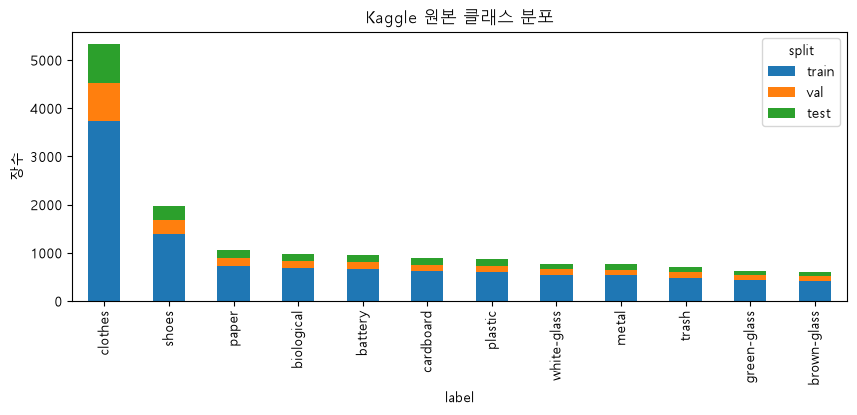

split,train,val,test,total
label,,,,
clothes,3727,799,799,5325
shoes,1384,296,297,1977
paper,735,157,158,1050
biological,689,148,148,985
battery,661,142,142,945
cardboard,624,133,134,891
plastic,606,129,130,865
white-glass,543,116,116,775
metal,538,116,115,769


In [3]:
# [셀 목적] 클래스별 장수 표와 분포 그래프 — 클래스 불균형 확인 (최다/최소 비율)
class_counts = pd.crosstab(split.label, split.split)[["train", "val", "test"]]
class_counts["total"] = class_counts.sum(axis=1)
class_counts = class_counts.sort_values("total", ascending=False)
print(f"불균형: 최다 {class_counts.total.idxmax()} {class_counts.total.max()}장 / 최소 {class_counts.total.idxmin()} "
      f"{class_counts.total.min()}장 = {class_counts.total.max() / class_counts.total.min():.2f}배")
ax = class_counts[["train", "val", "test"]].plot.bar(stacked=True, figsize=(10, 3.5), title="Kaggle 원본 클래스 분포")
ax.set_ylabel("장수")
plt.show()
class_counts

## 3. 외부 데이터 통합 → 학습 데이터(train_mix)와 외부 검증셋(val_ext)
Kaggle 사진은 대부분 단색 배경이라, 실제 환경 사진이나 생성형 이미지와 분위기가 다르다. 그래서 실사 외부 데이터를 섞는다.

| 출처 | 사용 클래스 | 비고 |
|---|---|---|
| Garbage Classification V2 (Kaggle, sumn2u) | biological·cardboard·metal·paper·plastic·trash | glass는 색 라벨이 없어 제외 |
| RealWaste (UCI, CC BY-NC-SA 4.0) | Food Organics→biological, Misc Trash→trash, Cardboard·Metal·Paper·Plastic | Glass·Vegetation·Textile 제외 |
| AI Hub 재활용품 분류 및 선별 데이터 (직접촬영) | 유리병 갈색·녹색·투명(→white-glass), 건전지(→battery), 철캔(→metal) | zip에서 필요한 만큼만 꺼내 짧은 변 384px로 저장 |

**처리 순서**
1. **중복 제거**: perceptual hash 거리 4 이하를 같은 사진으로 본다.
   - Kaggle 전체(train·val·test)와 겹치는 외부 사진은 제거한다. 라벨이 다르면 '충돌'로 보고 제외한다.
   - 외부 사진끼리 겹칠 때도 같은 기준으로 처리한다.
   - 이렇게 해야 검증·테스트 사진이 학습 데이터로 새어 들어가지 않는다.
2. **외부 검증셋 val_ext를 먼저 떼어 고정**: RealWaste·AI Hub에서 클래스당 50장씩 10클래스, 총 500장이다.
3. **학습 데이터 train_mix 구성**: 남은 외부 사진과 Kaggle train을 섞어 클래스당 1,000장, 총 12,000장을 만든다. 외부 사진이 모자라면 Kaggle로 채운다.

In [4]:
# [셀 목적] 외부 데이터 설정값 — 클래스 매핑, AI Hub zip 목록, 클래스별 학습 데이터 구성표, 외부 검증셋 구성표
HAM = 4  # 중복 판정 hamming 거리
V2_MAP = {c: c for c in ["biological", "cardboard", "metal", "paper", "plastic", "trash"]}
RW_MAP = {"Food Organics": "biological", "Miscellaneous Trash": "trash", "Cardboard": "cardboard",
          "Metal": "metal", "Paper": "paper", "Plastic": "plastic"}
# AI Hub zip → (클래스, 꺼낼 후보 수). 후보 수 = 필요량 × 약 1.35 (중복 제거 여유분)
AI_ZIPS = [
    ("Validation/01.원천데이터/VS_2.직접촬영_07.유리병_001.갈색.zip", "brown-glass", 850),
    ("Validation/01.원천데이터/VS_2.직접촬영_07.유리병_002.녹색.zip", "green-glass", 830),
    ("Validation/01.원천데이터/VS_2.직접촬영_07.유리병_003.투명.zip", "white-glass", 810),
    ("Training/01.원천데이터/TS_2.직접촬영_08.건전지_001.건전지.zip", "battery", 650),
    ("Validation/01.원천데이터/VS_2.직접촬영_08.건전지_001.건전지.zip", "battery", 150),
    ("Training/01.원천데이터/TS_2.직접촬영_01.금속캔_001.철캔_3.zip", "metal", 200),
]
# 학습 데이터 구성표: 클래스 → {출처: 장수} (클래스당 1,000장, 외부 약 47%)
TRAIN_PLAN = {
    "battery": {"kaggle": 500, "aihub": 500},
    "biological": {"kaggle": 579, "v2": 60, "realwaste": 361},
    "brown-glass": {"kaggle": 425, "aihub": 575},
    "green-glass": {"kaggle": 440, "aihub": 560},
    "white-glass": {"kaggle": 450, "aihub": 550},
    "cardboard": {"kaggle": 400, "v2": 300, "realwaste": 300},
    "clothes": {"kaggle": 1000},
    "metal": {"kaggle": 400, "v2": 200, "realwaste": 300, "aihub": 100},
    "paper": {"kaggle": 400, "v2": 300, "realwaste": 300},
    "plastic": {"kaggle": 400, "v2": 300, "realwaste": 300},
    "shoes": {"kaggle": 1000},
    "trash": {"kaggle": 400, "v2": 200, "realwaste": 400},
}
# 외부 검증셋 구성표: clothes·shoes는 RealWaste·AI Hub에 없어 제외 (10클래스 × 50 = 500)
VAL_EXT_PLAN = {
    "battery": {"aihub": 50}, "brown-glass": {"aihub": 50}, "green-glass": {"aihub": 50},
    "white-glass": {"aihub": 50}, "biological": {"realwaste": 50}, "trash": {"realwaste": 50},
    "cardboard": {"realwaste": 50}, "paper": {"realwaste": 50}, "plastic": {"realwaste": 50},
    "metal": {"realwaste": 25, "aihub": 25},
}

In [5]:
# [셀 목적] 외부 데이터 처리 함수 — AI Hub zip 추출, 폴더 목록화, perceptual hash 계산, 최소 해시 거리 계산
def extract_aihub() -> pd.DataFrame:
    """AI Hub zip에서 seed 고정으로 필요한 수만 꺼내 짧은 변 384px JPEG로 저장 (이미 있으면 건너뜀)"""
    rows = []
    for zrel, label, n in AI_ZIPS:
        out_dir = AIHUB_OUT / label
        out_dir.mkdir(parents=True, exist_ok=True)
        with zipfile.ZipFile(AIHUB_ZIP_DIR / zrel) as zf:
            names = sorted(i.filename for i in zf.infolist() if not i.is_dir() and i.filename.lower().endswith(".jpg"))
            pick = random.Random(SEED).sample(names, min(n, len(names)))
            broken = 0
            for name in pick:
                dst = out_dir / Path(name).name
                if not dst.exists():
                    try:
                        img = Image.open(io.BytesIO(zf.read(name)))
                        img.draft("RGB", (768, 768))  # 큰 JPEG를 빠르게 축소 디코딩
                        img = ImageOps.exif_transpose(img).convert("RGB")
                    except Exception:  # zip 안의 깨진 파일은 건너뜀
                        broken += 1
                        continue
                    s = 384 / min(img.size)
                    if s < 1:
                        img = img.resize((round(img.width * s), round(img.height * s)), Image.BILINEAR)
                    img.save(dst, quality=92)
                rows.append(dict(path=rel(dst), label=label, source="aihub", origin=f"{Path(zrel).name}/{name}"))
    return pd.DataFrame(rows)


def list_folder(base: Path, mapping: dict, source: str) -> pd.DataFrame:
    """원본 폴더(클래스별 하위 폴더)를 우리 12클래스 라벨로 매핑해 목록화"""
    rows = []
    for src_cls, label in mapping.items():
        for f in sorted((base / src_cls).iterdir()):
            if f.suffix.lower() in IMG_EXT:
                rows.append(dict(path=rel(f), label=label, source=source, origin=f"{src_cls}/{f.name}"))
    return pd.DataFrame(rows)


def phash_all(paths, cache: dict) -> np.ndarray:
    """각 이미지의 64bit perceptual hash (캐시에 있으면 재사용)"""
    out = np.zeros(len(paths), dtype=np.uint64)
    for i, p in enumerate(paths):
        if p not in cache:
            with Image.open(ROOT / p) as im:
                im.draft("L", (128, 128))
                cache[p] = str(imagehash.phash(im.convert("L")))
        out[i] = np.uint64(int(cache[p], 16))
    return out


def min_ham(a: np.ndarray, b: np.ndarray, chunk=400):
    """a의 각 해시에 대해 b 중 가장 가까운 hamming 거리와 그 위치 (메모리 절약을 위해 400개씩 나눠 계산)"""
    dmin = np.full(len(a), 99, dtype=np.int64)
    arg = np.zeros(len(a), dtype=np.int64)
    for s in range(0, len(a), chunk):
        d = np.bitwise_count(a[s:s + chunk, None] ^ b[None, :]).astype(np.int64)
        arg[s:s + chunk] = d.argmin(1)
        dmin[s:s + chunk] = d.min(1)
    return dmin, arg

In [6]:
# [셀 목적] train_mix.csv·val_ext.csv가 없을 때만: 중복 제거 → 외부 검증셋 고정 → 학습 데이터 12,000장 구성. 있으면 읽기만
mix_path, val_ext_path = DATA_DIR / "train_mix.csv", DATA_DIR / "val_ext.csv"
if mix_path.exists() and val_ext_path.exists():
    train_mix, val_ext = pd.read_csv(mix_path), pd.read_csv(val_ext_path)
    print("기존 train_mix.csv·val_ext.csv 사용 (고정, 재생성 안 함)")
else:
    random.seed(SEED)
    ext = pd.concat([list_folder(V2_DIR, V2_MAP, "v2"), list_folder(RW_DIR, RW_MAP, "realwaste"), extract_aihub()],
                    ignore_index=True)
    cache = json.loads(PHASH_CACHE.read_text()) if PHASH_CACHE.exists() else {}
    hk = phash_all(split["path"].tolist(), cache)
    he = phash_all(ext["path"].tolist(), cache)
    PHASH_CACHE.write_text(json.dumps(cache))

    # ① Kaggle 전체(train·val·test)와 비교: 같은 라벨 근접 = 중복, 다른 라벨 근접 = 라벨 충돌 → 둘 다 제외
    d, j = min_ham(he, hk)
    near = d <= HAM
    same = near & (split["label"].values[j] == ext["label"].values)
    ext["status"] = "keep"
    ext.loc[same, "status"] = "dup_kaggle"
    ext.loc[near & ~same, "status"] = "conflict_kaggle"

    # ② 외부끼리 비교: 같은 라벨 근접 → 1장만 유지(AI Hub > RealWaste > V2 우선), 다른 라벨 근접 → 양쪽 제외
    idx = np.where(ext["status"] == "keep")[0]
    h = he[idx]
    labels = ext["label"].values[idx]
    order = {"aihub": 0, "realwaste": 1, "v2": 2}
    pri = np.array([order[s] for s in ext["source"].values[idx]])
    drop_dup, drop_conf = set(), set()
    for s in range(0, len(idx), 400):
        dd = np.bitwise_count(h[s:s + 400, None] ^ h[None, :])
        for r, c in zip(*np.where(dd <= HAM)):
            a, b = s + r, c
            if a >= b:
                continue
            if labels[a] != labels[b]:
                drop_conf.update([a, b])
            else:
                drop_dup.add(b if (pri[a], a) <= (pri[b], b) else a)
    ext.loc[idx[sorted(drop_dup - drop_conf)], "status"] = "dup_external"
    ext.loc[idx[sorted(drop_conf)], "status"] = "conflict_external"
    report = ext.pivot_table(index=["source", "label"], columns="status", values="path", aggfunc="count", fill_value=0)
    report.to_csv(DATA_DIR / "dedup_report.csv", encoding="utf-8-sig")
    pool = ext[ext["status"] == "keep"].copy()

    # ③ 외부 검증셋(val_ext) 먼저 고정
    ve = []
    for label, srcs in VAL_EXT_PLAN.items():
        for src, n in srcs.items():
            cand = pool[(pool.label == label) & (pool.source == src)]
            ve.append(cand.sample(n=min(n, len(cand)), random_state=SEED))
    val_ext = pd.concat(ve)
    pool = pool.drop(val_ext.index)

    # ④ 학습 데이터: 구성표대로 외부 사진을 뽑고, 모자란 만큼 Kaggle train으로 채워 클래스당 1,000장
    k_train = split[split["split"] == "train"]
    tr = []
    for label, srcs in TRAIN_PLAN.items():
        got = 0
        for src, n in srcs.items():
            if src == "kaggle":
                continue
            cand = pool[(pool.label == label) & (pool.source == src)]
            take = cand.sample(n=min(n, len(cand)), random_state=SEED)
            tr.append(take)
            got += len(take)
        kc = k_train[k_train.label == label]
        tr.append(kc.sample(n=min(1000 - got, len(kc)), random_state=SEED).assign(origin="split.csv"))
    train_mix = pd.concat(tr)

    cols = ["path", "label", "split", "source"]
    train_mix = train_mix.assign(split="train")[cols].sort_values(["label", "source", "path"]).reset_index(drop=True)
    val_ext = val_ext.assign(split="val_ext")[cols].sort_values(["label", "source", "path"]).reset_index(drop=True)
    train_mix.to_csv(mix_path, index=False, encoding="utf-8")
    val_ext.to_csv(val_ext_path, index=False, encoding="utf-8")
    print("train_mix.csv·val_ext.csv 새로 생성")

# 누출 검사: 학습 데이터 ∩ 외부 검증셋 = ∅, 외부 검증셋 ∩ Kaggle = ∅, 학습 데이터의 Kaggle 사진은 Kaggle train에서만
assert not set(train_mix.path) & set(val_ext.path)
assert not set(val_ext.path) & set(split.path)
assert set(train_mix[train_mix.source == "kaggle"].path) <= set(split[split.split == "train"].path)
print("학습 데이터", len(train_mix), "장:", train_mix.source.value_counts().to_dict())
print("외부 검증셋", len(val_ext), "장:", val_ext.source.value_counts().to_dict())
pd.crosstab(train_mix.label, train_mix.source)

기존 train_mix.csv·val_ext.csv 사용 (고정, 재생성 안 함)
학습 데이터 12000 장: {'kaggle': 6396, 'aihub': 2285, 'realwaste': 1959, 'v2': 1360}
외부 검증셋 500 장: {'realwaste': 275, 'aihub': 225}


source,aihub,kaggle,realwaste,v2
label,,,,
battery,500,500,0,0
biological,0,581,359,60
brown-glass,575,425,0,0
cardboard,0,400,300,300
clothes,0,1000,0,0
green-glass,560,440,0,0
metal,100,400,300,200
paper,0,400,300,300
plastic,0,400,300,300


In [7]:
# [셀 목적] 중복 제거 결과 표 — 출처·클래스별로 유지(keep) / Kaggle 중복 / 라벨 충돌 / 외부끼리 중복 장수
pd.read_csv(DATA_DIR / "dedup_report.csv", index_col=[0, 1])

conflict_external  conflict_kaggle  dup_external  dup_kaggle  keep
source    label                                                                          
aihub     battery                      3                2             1           0   794
          brown-glass                  6                5             2           0   837
          green-glass                  5                0             2           0   822
          metal                        1                0             1           0   198
          white-glass                  2                0             0           0   808
realwaste biological                   0                0             2           0   409
          cardboard                    2                0             0           0   459
          metal                        2                1             1           0   786
          paper                        0                0             0           0   500
          plastic                      4                2             6           0   909
          trash                        0                3             1           0   491
v2        biological                   0                0             0         639    60
          cardboard                    0                5             0         710   696
          metal                        0                0             0         611   319
          paper                        1                1             0         603   731
          plastic                      0                0             0         633   964
          trash                        0                0             0         231   222

## 4. 손상 검증셋(val_hard) 생성 — 어둡거나 흐리거나 빛이 번진 사진
채점 이미지에는 어둡거나 흐린 사진이 섞일 수 있다. 이런 사진에서 모델이 얼마나 버티는지 따로 재기 위해 고정된 손상 검증셋을 만든다.
- **구성** (1,200장)
  - Kaggle val에서 클래스당 50장. clothes·shoes는 외부 사진이 없어 100장씩 → 700장
  - 외부 검증셋 500장
- **손상**: 160×160으로 줄인 뒤 seed를 고정해 3종 중 하나를 적용한다.
  - 흐림: Gaussian 반경 2~3
  - 어둡게: 밝기 0.15~0.35배
  - 빛번짐: 흰 원형 광원 합성
- 학습 증강(밝기 0.3~1.0, 흐림 σ 0.5~2)보다 **더 강하게** 만들었다. 빛번짐은 학습에 아예 없는 손상이라, 처음 보는 손상에 대한 일반화도 볼 수 있다.

In [8]:
# [셀 목적] 손상 함수(흐림·어둡게·빛번짐) 정의 + val_hard.csv가 없을 때만 손상 이미지 1,200장 생성 (있으면 읽기만)
def glare(img: Image.Image, rng: random.Random) -> Image.Image:
    """무작위 위치에 흰 원형 빛번짐을 screen 합성"""
    a = np.asarray(img, dtype=np.float32) / 255.0
    h, w = a.shape[:2]
    cy, cx = rng.uniform(0.15, 0.85) * h, rng.uniform(0.15, 0.85) * w
    r = rng.uniform(0.25, 0.45) * min(h, w)
    yy, xx = np.mgrid[0:h, 0:w]
    m = np.clip(1 - np.sqrt((yy - cy) ** 2 + (xx - cx) ** 2) / r, 0, 1) ** 1.5 * rng.uniform(0.6, 0.9)
    a = 1 - (1 - a) * (1 - m[..., None])
    return Image.fromarray((a * 255).clip(0, 255).astype(np.uint8))


def corrupt(img: Image.Image, kind: str, rng: random.Random) -> Image.Image:
    if kind == "blur":
        return img.filter(ImageFilter.GaussianBlur(rng.uniform(2.0, 3.0)))
    if kind == "dark":
        return ImageEnhance.Brightness(img).enhance(rng.uniform(0.15, 0.35))
    return glare(img, rng)


val_hard_path = DATA_DIR / "val_hard.csv"
if val_hard_path.exists():
    val_hard = pd.read_csv(val_hard_path)
    print("기존 val_hard.csv 사용 (고정, 재생성 안 함)")
else:
    val = split[split["split"] == "val"]
    parts = [g.sample(n=100 if c in ("clothes", "shoes") else 50, random_state=SEED) for c, g in val.groupby("label")]
    src = pd.concat(parts + [val_ext], ignore_index=True).sort_values(["label", "source", "path"]).reset_index(drop=True)
    rng = random.Random(SEED)
    rows = []
    for i, r in src.iterrows():
        kind = rng.choice(["blur", "dark", "glare"])
        img = Image.open(ROOT / r.path).convert("RGB").resize((160, 160), Image.BILINEAR)
        p = VAL_HARD_IMG / r.label / f"{i:04d}_{kind}.png"
        p.parent.mkdir(parents=True, exist_ok=True)
        corrupt(img, kind, rng).save(p)
        rows.append(dict(path=rel(p), label=r.label, split="val_hard", source=r.source, orig_path=r.path, corruption=kind))
    val_hard = pd.DataFrame(rows)
    val_hard.to_csv(val_hard_path, index=False, encoding="utf-8")
    print("val_hard.csv 새로 생성")

print("손상 검증셋", len(val_hard), "장 | 손상별", val_hard.corruption.value_counts().to_dict(),
      "| 출처별", val_hard.source.value_counts().to_dict())

기존 val_hard.csv 사용 (고정, 재생성 안 함)


손상 검증셋 1200 장 | 손상별 {'dark': 408, 'glare': 397, 'blur': 395} | 출처별 {'kaggle': 700, 'realwaste': 275, 'aihub': 225}


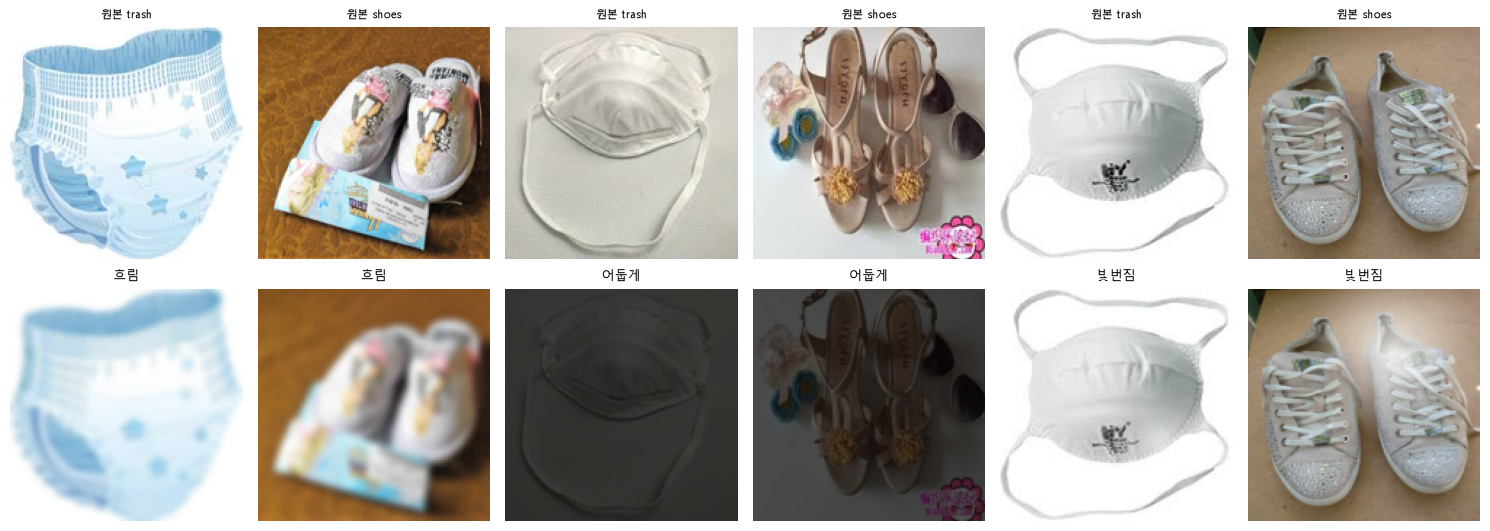

In [9]:
# [셀 목적] 손상 검증셋 예시 — 원본(위)과 손상 버전(아래) 6쌍 (이미지 파일이 있을 때만 표시)
ex = pd.concat([(lambda g: g.sample(min(2, len(g)), random_state=SEED))(val_hard[val_hard.corruption == k].drop_duplicates("label"))
                for k in ["blur", "dark", "glare"]])  # 손상 종류마다 서로 다른 클래스 2장
if all((ROOT / p).exists() for p in list(ex.path) + list(ex.orig_path)):
    fig, ax = plt.subplots(2, max(len(ex), 1), figsize=(15, 5.5), squeeze=False)
    for k, r in enumerate(ex.itertuples()):
        ax[0, k].imshow(Image.open(ROOT / r.orig_path).convert("RGB").resize((160, 160)))
        ax[0, k].set_title(f"원본 {r.label}", fontsize=8)
        ax[1, k].imshow(Image.open(ROOT / r.path))
        ax[1, k].set_title({"blur": "흐림", "dark": "어둡게", "glare": "빛번짐"}[r.corruption], fontsize=9)
    for a in ax.ravel():
        a.axis("off")
    plt.tight_layout()
    plt.show()
else:
    print("이미지 파일이 없어 예시를 생략 (저장소에는 이미지 미포함)")

## 5. 외부 테스트셋(test_ext) 생성 — 최종 평가 보조용
Kaggle test는 깨끗한 사진뿐이라, 실제 채점 이미지(생성형·실사)에 가까운 외부 사진으로도 최종 점수를 확인한다.
- **구성**: 학습 데이터와 외부 검증셋에 쓰지 않고 남은 외부 사진(AI Hub·RealWaste)에서 9클래스 × 40장 = 360장
  - biological·clothes·shoes는 남은 외부 사진이 없어 제외했다.
- **안전 재검사**: Kaggle 전체, 학습 데이터, 외부 검증셋과 해시가 가까운 사진은 뺀다. 남은 사진끼리 가까운 쌍도 둘 다 뺀다(같은 물체를 반복 촬영한 사진 방지).
- 학습·모델 선택에는 쓰지 않고, **Kaggle test와 함께 마지막에 한 번만** 평가한다.

In [10]:
# [셀 목적] test_ext.csv가 없을 때만: 남은 외부 사진에서 해시 재검사 후 9클래스 × 40장 추출 (있으면 읽기만)
TEST_EXT_PLAN = {
    "battery": {"aihub": 40}, "brown-glass": {"aihub": 40}, "green-glass": {"aihub": 40},
    "white-glass": {"aihub": 40}, "metal": {"aihub": 20, "realwaste": 20},
    "cardboard": {"realwaste": 40}, "paper": {"realwaste": 40}, "plastic": {"realwaste": 40},
    "trash": {"realwaste": 40},
}
test_ext_path = DATA_DIR / "test_ext.csv"
if test_ext_path.exists():
    test_ext = pd.read_csv(test_ext_path)
    print("기존 test_ext.csv 사용 (고정, 재생성 안 함)")
else:
    used = set(train_mix.path) | set(val_ext.path)
    aihub_files = pd.DataFrame([dict(path=rel(f), label=d.name, source="aihub")
                                for d in sorted(AIHUB_OUT.iterdir()) if d.is_dir() for f in sorted(d.iterdir())])
    ext = pd.concat([list_folder(V2_DIR, V2_MAP, "v2"), list_folder(RW_DIR, RW_MAP, "realwaste"), aihub_files],
                    ignore_index=True)[["path", "label", "source"]]
    ext = ext[~ext.path.isin(used)].reset_index(drop=True)
    cache = json.loads(PHASH_CACHE.read_text())
    he = phash_all(ext.path.tolist(), cache)
    ref = pd.concat([split[["path"]], train_mix[["path"]], val_ext[["path"]]]).drop_duplicates()
    hr = phash_all(ref.path.tolist(), cache)
    PHASH_CACHE.write_text(json.dumps(cache))
    d, _ = min_ham(he, hr)
    keep = d > HAM                                   # 이미 쓰인 사진·Kaggle 전체와 근접 → 제외
    if len(he) < 6000:                               # 풀 내부 근접쌍 → 양쪽 제외
        dd = np.bitwise_count(he[:, None] ^ he[None, :])
        np.fill_diagonal(dd, 99)
        keep &= dd.min(1) > HAM
    ext = ext[keep].reset_index(drop=True)
    te = []
    for label, srcs in TEST_EXT_PLAN.items():
        for src, n in srcs.items():
            cand = ext[(ext.label == label) & (ext.source == src)]
            assert len(cand) >= n, f"{label}/{src}: {len(cand)} < {n}"
            te.append(cand.sample(n=n, random_state=SEED))
    test_ext = pd.concat(te).assign(split="test_ext")[["path", "label", "split", "source"]].sort_values(["label", "source", "path"]).reset_index(drop=True)
    test_ext.to_csv(test_ext_path, index=False, encoding="utf-8")
    print("test_ext.csv 새로 생성")

# 누출 검사: 외부 테스트셋은 학습 데이터·외부 검증셋·Kaggle 어디에도 없어야 함
assert not set(test_ext.path) & (set(train_mix.path) | set(val_ext.path) | set(split.path))
print("외부 테스트셋", len(test_ext), "장:", test_ext.source.value_counts().to_dict())

기존 test_ext.csv 사용 (고정, 재생성 안 함)
외부 테스트셋 360 장: {'aihub': 180, 'realwaste': 180}


### 데이터 정리 — 사진을 직접 확인해 부적절한 사진을 걸러낸 최종 분할

1차 튜닝(R1~R12)을 마친 뒤, 2차를 위해 외부 데이터를 더 모았다. 새로 모은 사진과 기존 외부 사진을 눈으로 확인하는 과정에서 **라벨과 맞지 않거나 쓸 수 없는 사진**(예: 갈색 유리 라벨의 초록 병, 종이 라벨의 크래프트지, 골판지 라벨의 우유팩)이 새 데이터뿐 아니라 1차 분할(val_ext·test_ext 포함)에도 섞여 있음을 발견했다. 그래서 모든 분할에 같은 기준으로 정리를 적용했다. 1차 튜닝의 결과 수치는 정리 전 1차 분할에서 측정한 값이며, 이후 실험은 정리본으로 한다.

**제외 기준**
1. **AI Hub 유리 사진**: 병이 사진의 2% 미만으로 작거나, 병 색이 라벨(갈색·녹색·투명)과 다르면 제외한다 (`glass_check.py`).
2. **육안 검토 제외 목록**: 사진을 직접 보고 고른 목록이다. `split_rejects.csv`는 val_ext 29장·test_ext 19장·학습 v2 paper 76장, `extra_rejects.csv`는 추가 v2 paper 150장이다.
3. **v2 cardboard**: 우유팩·플라스틱 병이 많이 섞여 있어 전부 제외한다.

**보충 방식**: 제외로 빠진 장수는 test_ext → val_ext 순서로, **같은 출처·같은 클래스의 아직 안 쓴 깨끗한 사진**으로 채워 장수와 클래스 구성을 유지한다.

**추가한 외부 데이터 출처**: AI Hub 직접촬영(추가분), TrashBusters/combined(Hugging Face, MIT: TriCascade·Household 일부·캔 이외 금속), Recyclable and Household Waste(Kaggle, 옷·신발·종이를 육안으로 골라 사용), ShoeSandalBoot(Hugging Face), RealWaste·v2 미사용분.

**결과**: 학습 27,050장 / val_ext 498장 / test_ext 360장 / val_hard 1,198장. val_hard는 Kaggle val 700장을 그대로 두고, 정리된 val_ext의 외부 사진을 손상시킨 사진으로 구성한다.

**알려진 한계**: val_ext의 biological·trash 49장, val_hard의 Kaggle 700장, 학습 v2 biological·metal·plastic·trash는 육안으로 점검하지 못했다.

정리 스크립트는 기록용으로 `01_coding/tools/`에 두었다 (원본 AI Hub 196GB가 있어야 실행 가능하므로 노트북에서는 실행하지 않고, 만들어진 `*_clean.csv`만 읽는다).

In [11]:
# [셀 목적] 1차 분할을 *_v1 이름으로 보관하고, 정리된 분할(*_clean.csv)을 train_mix·val_ext·test_ext·val_hard로 읽기
train_mix_v1, val_ext_v1, test_ext_v1, val_hard_v1 = train_mix, val_ext, test_ext, val_hard   # 1차 분할 (표시용으로만 보관)

clean_files = {n: DATA_DIR / f"{n}_clean.csv" for n in ["train_mix", "val_ext", "test_ext", "val_hard"]}
missing = [f.name for f in clean_files.values() if not f.exists()]
if missing:
    raise FileNotFoundError(f"정리된 분할 파일이 없음: {missing} → 01_coding/tools/clean_splits.py를 실행해 만들어야 함. Colab이면 Drive의 split_and_results.zip이 최신인지 확인")
train_mix, val_ext, test_ext, val_hard = (pd.read_csv(clean_files[n]) for n in ["train_mix", "val_ext", "test_ext", "val_hard"])

# 누출 검사: 학습·val_ext·test_ext는 서로 겹치면 안 되고, val_hard의 원본 사진도 학습에 없어야 한다
_tr, _ve, _te = set(train_mix.path), set(val_ext.path), set(test_ext.path)
assert not _tr & _ve and not _tr & _te and not _ve & _te, "정리된 분할끼리 겹치는 사진이 있음"
assert not (_tr | _ve | _te) & set(split[split.split != "train"].path), "정리된 분할에 1차 val·test 사진이 들어 있음"
assert not set(val_hard.orig_path) & _tr, "val_hard 원본 사진이 학습 데이터에 있음"
assert not set(val_hard.orig_path) & _te, "val_hard 원본 사진이 test_ext에 있음"
print(f"정리본: 학습 {len(train_mix):,} / val_ext {len(val_ext):,} / test_ext {len(test_ext):,} / val_hard {len(val_hard):,}"
      f"  (1차: {len(train_mix_v1):,} / {len(val_ext_v1):,} / {len(test_ext_v1):,} / {len(val_hard_v1):,})")


정리본: 학습 27,050 / val_ext 498 / test_ext 360 / val_hard 1,198  (1차: 12,000 / 500 / 360 / 1,200)


In [12]:
# [셀 목적] 추가 외부 데이터 장수, 정리(제외) 요약, 학습·val_ext·test_ext의 클래스×출처 장수(비율) 표 출력
extra_counts = pd.read_csv(DATA_DIR / "extra_counts.csv", encoding="utf-8-sig")
print("추가 외부 데이터 클래스별 장수 (열 = 출처)")
display(extra_counts)

clean_report = pd.read_csv(DATA_DIR / "clean_report.csv", encoding="utf-8-sig")
print("정리에서 제외된 장수 (분할 × 제외 사유)")
display(clean_report.pivot_table(index="set", columns="reason", values="n", aggfunc="sum", fill_value=0))

for _name, _df in [("학습 데이터", train_mix), ("val_ext", val_ext), ("test_ext", test_ext)]:
    _tab = pd.crosstab(_df.label, _df.source)
    _tab["합계"] = _tab.sum(axis=1)
    _tab["비율(%)"] = (_tab["합계"] / len(_df) * 100).round(1)
    print(f"{_name}: 클래스 × 출처 장수 (합계 {len(_df):,})")
    display(_tab)


추가 외부 데이터 클래스별 장수 (열 = 출처)


,label,aihub,clothing,hf_shoes,household_default,household_real,metal_diverse,realwaste,tricascade,v2,추가 합계,기존 외부,외부 총계
0,battery,1500,0,0,0,0,0,0,0,0,1500,500,2000
1,biological,0,0,0,80,411,0,0,1090,0,1581,419,2000
2,brown-glass,705,0,0,0,0,0,0,0,0,705,575,1280
3,cardboard,0,0,0,169,384,0,70,777,0,1400,600,2000
4,clothes,0,23,0,81,60,0,0,0,1,165,0,165
5,green-glass,762,0,0,0,0,0,0,0,0,762,560,1322
6,metal,474,0,0,0,0,474,442,0,10,1400,600,2000
7,paper,0,0,0,233,111,0,110,537,282,1273,600,1873
8,plastic,0,0,0,136,342,0,341,240,341,1400,600,2000
9,shoes,0,2,1631,235,132,0,0,0,0,2000,0,2000


정리에서 제외된 장수 (분할 × 제외 사유)


reason,v2 cardboard,보충(aihub),보충(realwaste),유리 작음·색 불일치,육안 제외,재생성
set,,,,,,
test_ext,0,55,17,53,19,0
train_mix,300,0,0,814,76,0
val_ext,0,82,19,74,29,0
val_hard,0,0,0,0,0,101


학습 데이터: 클래스 × 출처 장수 (합계 27,050)


source,aihub,clothing,hf_shoes,household_default,household_real,kaggle,metal_diverse,realwaste,tricascade,v2,합계,비율(%)
label,,,,,,,,,,,,
battery,2000,0,0,0,0,661,0,0,0,0,2661,9.8
biological,0,0,0,80,411,689,0,359,1090,60,2689,9.9
brown-glass,979,0,0,0,0,425,0,0,0,0,1404,5.2
cardboard,0,0,0,169,384,624,0,346,777,0,2300,8.5
clothes,0,23,0,81,60,2835,0,0,0,1,3000,11.1
green-glass,1066,0,0,0,0,440,0,0,0,0,1506,5.6
metal,564,0,0,0,0,538,474,742,0,210,2528,9.3
paper,0,0,0,233,111,735,0,400,537,506,2522,9.3
plastic,0,0,0,136,342,606,0,640,240,641,2605,9.6


val_ext: 클래스 × 출처 장수 (합계 498)


source,aihub,realwaste,합계,비율(%)
label,,,,
battery,50,0,50,10.0
biological,0,49,49,9.8
brown-glass,50,0,50,10.0
cardboard,0,50,50,10.0
green-glass,50,0,50,10.0
metal,25,25,50,10.0
paper,0,50,50,10.0
plastic,0,50,50,10.0
trash,0,49,49,9.8


test_ext: 클래스 × 출처 장수 (합계 360)


source,aihub,realwaste,합계,비율(%)
label,,,,
battery,40,0,40,11.1
brown-glass,40,0,40,11.1
cardboard,0,40,40,11.1
green-glass,40,0,40,11.1
metal,20,20,40,11.1
paper,0,40,40,11.1
plastic,0,40,40,11.1
trash,0,40,40,11.1
white-glass,40,0,40,11.1


### 데이터셋 정리

| 이름 | 장수 | 구성 | 용도 |
|---|---|---|---|
| 학습 데이터 (train_mix) | 27,050 | Kaggle 원본 + 외부 데이터(정리본, 위 표 참고) | 학습 |
| **val** — 기본 검증 | 2,327 | Kaggle 원본 분할 15% (깨끗한 사진) | 조기 종료·선택 |
| **val_ext** — 외부 검증 | 498 | 정리된 외부 실사 사진 | 조기 종료·선택 |
| **val_hard** — 손상 검증 | 1,198 | Kaggle val 700장 + 정리된 val_ext 외부 사진 손상본 (흐림·어둡게·빛번짐) | 선택 |
| **test** — 기본 테스트 | 2,328 | Kaggle 원본 분할 15% | 최종 1회 |
| **test_ext** — 외부 테스트 | 360 | 정리된 외부 실사 사진 | 최종 1회 |

(1차 분할은 학습 12,000 / val_ext 500 / val_hard 1,200 / test_ext 360이었다. 위는 정리본 기준이다.)

In [13]:
# [셀 목적] 모든 데이터셋의 장수·클래스 수를 한 표로 확인
sets_summary = pd.DataFrame({
    "장수": [len(train_mix), (split.split == "val").sum(), len(val_ext), len(val_hard), (split.split == "test").sum(), len(test_ext)],
    "클래스 수": [train_mix.label.nunique(), split[split.split == "val"].label.nunique(), val_ext.label.nunique(),
               val_hard.label.nunique(), split[split.split == "test"].label.nunique(), test_ext.label.nunique()],
}, index=["학습 데이터", "val", "val_ext", "val_hard", "test", "test_ext"])
sets_summary

,장수,클래스 수
학습 데이터,27050,12
val,2327,12
val_ext,498,10
val_hard,1198,12
test,2328,12
test_ext,360,9


## 6. 이미지 캐시·전처리·증강
- **캐시**: 원본 사진(수백 px~수천 px)을 매 epoch 읽고 줄이면 느리다. 그래서 모든 사진을 **192×192로 한 번만 줄여 PNG로 저장**하고, 학습할 때는 이 파일을 읽는다. 줄이는 방식은 두 가지다.
  - `squash`: 가로·세로를 각각 192로 맞춘다. 직사각형 사진은 찌그러진다(1차 방식, 기록용으로 남겨 둠).
  - `letterbox`(비율 유지): 긴 변을 192로 맞추고, 남는 위아래(또는 좌우)는 평균 색으로 채워 정사각형을 만든다. 물체 모양이 찌그러지지 않는다. 이 캐시는 `192_lb` 폴더에 따로 저장한다.
- **정규화**: 정리된 학습 데이터 사진 2,000장(무작위, seed 42)에서 구한 RGB 평균·표준편차를 쓴다(`norm_stats_clean.json`, 1차 값 파일은 그대로 둠). 사전학습을 하지 않으므로 ImageNet 값을 쓸 이유가 없다. 이 평균 색은 비율 유지 여백과 회전으로 생기는 빈 모서리를 채우는 색으로도 쓴다.
- **학습 증강** (실험에서 하나씩 켠다)
  - 모양: `hflip`(좌우반전), `vflip`(상하반전), `rot`(±20도 회전)
  - 색: `color`(밝기·대비·채도·색조를 조금 흔듦), `trivial`(TrivialAugmentWide: 사진마다 무작위 변형 하나를 무작위 세기로 적용), `dark_blur`(50% 확률로 어둡게 또는 흐림)
  - `rrc`(무작위 자르기)는 1차 실험 기록용으로만 남겼고 이번에는 쓰지 않는다. 쓰레기는 물체의 일부만 잘려 나오면 다른 클래스처럼 보일 수 있기 때문이다.
- 검증·테스트에는 증강 없이 리사이즈와 정규화만 한다.


In [14]:
# [셀 목적] 192px 이미지 캐시 함수(찌그러뜨리기·비율 유지), 정규화 통계(정리된 학습 데이터), 증강 transform, Dataset·DataLoader 정의
CACHE_SIZE = 192


def letterbox(img: Image.Image, size: int, fill: tuple) -> Image.Image:
    """비율을 유지한 채 긴 변을 size로 맞추고, 남는 부분은 fill 색으로 채워 size×size 정사각형 만들기(사진은 가운데)"""
    w, h = img.size
    r = size / max(w, h)
    img = img.resize((max(1, round(w * r)), max(1, round(h * r))), Image.BILINEAR)
    canvas = Image.new("RGB", (size, size), tuple(fill))
    canvas.paste(img, ((size - img.width) // 2, (size - img.height) // 2))
    return canvas


def cache_resized(df: pd.DataFrame, cache_root: Path, size: int = CACHE_SIZE, name: str = "데이터",
                  mode: str = "squash") -> pd.DataFrame:
    """각 이미지를 RGB size×size PNG로 저장(이미 있으면 건너뜀). file 열(경로)을 붙여 반환.
    mode="squash": 찌그러뜨려 맞춤 → cache_root/<size>/<path>.png (1차 방식)
    mode="letterbox": 비율 유지 + 여백 채우기 → cache_root/<size>_lb/<path>.png"""
    assert mode in ("squash", "letterbox"), mode
    df = keep_available(df, name)            # 없는 파일(예: 내려받지 않은 AI Hub)은 제외하고 경고 출력
    folder = str(size) if mode == "squash" else f"{size}_lb"
    files = []
    for p in df["path"]:
        dst = Path(cache_root) / folder / (p + ".png")
        if not dst.exists():
            dst.parent.mkdir(parents=True, exist_ok=True)
            img = Image.open(ROOT / p).convert("RGB")
            img = img.resize((size, size), Image.BILINEAR) if mode == "squash" else letterbox(img, size, FILL)
            img.save(dst)
        files.append(str(dst))
    return df.assign(file=files)


# 정규화 통계: 정리된 학습 데이터 2,000장(seed 42)을 64px로 줄여 RGB 평균·표준편차를 구해 json으로 저장
# (1차의 norm_stats.json은 그대로 두고, 정리된 데이터용은 norm_stats_clean.json에 따로 둔다)
stats_path = DATA_DIR / "norm_stats_clean.json"
if stats_path.exists():
    MEAN, STD = json.load(open(stats_path, encoding="utf-8")).values()
else:
    _px = np.concatenate([np.asarray(Image.open(ROOT / p).convert("RGB").resize((64, 64)), dtype=np.float32).reshape(-1, 3) / 255
                          for p in keep_available(train_mix, "학습 데이터").sample(2000, random_state=SEED).path])
    MEAN = [round(float(v), 4) for v in _px.mean(0)]
    STD = [round(float(v), 4) for v in _px.std(0)]
    json.dump({"mean": MEAN, "std": STD}, open(stats_path, "w", encoding="utf-8"))
FILL = tuple(int(round(m * 255)) for m in MEAN)   # 여백·회전으로 생기는 빈 모서리를 채울 색(평균 색)
print("정규화 평균", MEAN, "표준편차", STD, "여백 색", FILL)


def build_transforms(img_size: int, aug: list):
    """aug 키워드(위에서부터 이 순서로 적용):
    모양 — 'rrc'(무작위 자르기, 1차 기록용), 'hflip'(좌우반전), 'vflip'(상하반전), 'rot'(±20도 회전)
    색 — 'color'(밝기·대비·채도·색조 약간 흔들기), 'trivial'(TrivialAugmentWide, 무작위 변형 하나), 'dark_blur'(어둡게 또는 흐림)
    반환 (학습 transform, 평가 transform)"""
    tf = [transforms.RandomResizedCrop(img_size, scale=(0.6, 1.0)) if "rrc" in aug else transforms.Resize((img_size, img_size))]
    if "hflip" in aug:
        tf.append(transforms.RandomHorizontalFlip())
    if "vflip" in aug:
        tf.append(transforms.RandomVerticalFlip())
    if "rot" in aug:
        tf.append(transforms.RandomRotation(20, fill=FILL))
    if "color" in aug:
        tf.append(transforms.ColorJitter(0.2, 0.2, 0.2, 0.03))
    if "trivial" in aug:
        tf.append(transforms.TrivialAugmentWide(fill=list(FILL)))
    if "dark_blur" in aug:
        tf.append(transforms.RandomApply([transforms.RandomChoice([
            transforms.ColorJitter(brightness=(0.3, 1.0)),   # 어둡게: 밝기 30~100%
            transforms.GaussianBlur(5, sigma=(0.5, 2.0)),    # 흐림
        ])], p=0.5))
    norm = [transforms.ToTensor(), transforms.Normalize(MEAN, STD)]
    return transforms.Compose(tf + norm), transforms.Compose([transforms.Resize((img_size, img_size))] + norm)


class GarbageDataset(Dataset):
    """df의 file 열(캐시 이미지 경로)과 label 로 (이미지 텐서, 클래스 번호)"""
    def __init__(self, df: pd.DataFrame, transform=None):
        self.files = df["file"].tolist()
        self.labels = [CLASS_TO_IDX[c] for c in df["label"]]
        self.transform = transform

    def __len__(self):
        return len(self.files)

    def __getitem__(self, i):
        img = Image.open(self.files[i]).convert("RGB")
        return (self.transform(img) if self.transform else img), self.labels[i]


def make_loader(df, tf, batch, shuffle):
    workers = 2 if IN_COLAB else 0   # Colab은 CPU 2개로 이미지 읽기를 병렬화, Windows 로컬은 0
    return DataLoader(GarbageDataset(df, tf), batch_size=batch, shuffle=shuffle, num_workers=workers,
                      pin_memory=DEVICE.type == "cuda", persistent_workers=workers > 0)


print(build_transforms(128, ["hflip", "vflip", "rot", "color", "trivial", "dark_blur"])[0])


정규화 평균 [0.6448, 0.6212, 0.5932] 표준편차 [0.2607, 0.2642, 0.2837] 여백 색 (164, 158, 151)
Compose(
    Resize(size=(128, 128), interpolation=bilinear, max_size=None, antialias=True)
    RandomHorizontalFlip(p=0.5)
    RandomVerticalFlip(p=0.5)
    RandomRotation(degrees=[-20.0, 20.0], interpolation=nearest, expand=False, fill=(164, 158, 151))
    ColorJitter(brightness=(0.8, 1.2), contrast=(0.8, 1.2), saturation=(0.8, 1.2), hue=(-0.03, 0.03))
    TrivialAugmentWide(num_magnitude_bins=31, interpolation=InterpolationMode.NEAREST, fill=[164, 158, 151])
    RandomApply(
    p=0.5
    RandomChoice(
    ColorJitter(brightness=(0.3, 1.0), contrast=None, saturation=None, hue=None)
    GaussianBlur(kernel_size=(5, 5), sigma=(0.5, 2.0))
)(p=None)
)
    ToTensor()
    Normalize(mean=[0.6448, 0.6212, 0.5932], std=[0.2607, 0.2642, 0.2837])
)


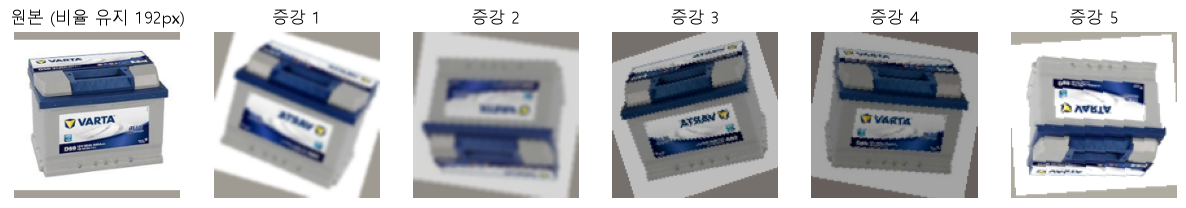

In [15]:
# [셀 목적] 학습 증강 예시 — 비율 유지 캐시 사진에 증강(좌우·상하반전, 회전, 색 흔들기, 어둡게/흐림)을 여러 번 적용한 결과
ex_path = next((ROOT / p for p in train_mix.path if (ROOT / p).exists()), None)  # 실제 있는 첫 학습 이미지
if ex_path is not None:
    img = letterbox(Image.open(ex_path).convert("RGB"), CACHE_SIZE, FILL)   # 비율 유지 방식 캐시 이미지
    show_tf = build_transforms(128, ["hflip", "vflip", "rot", "color", "dark_blur"])[0].transforms[:-2]   # 정규화 전 단계까지만
    random.seed(0)
    torch.manual_seed(0)
    fig, ax = plt.subplots(1, 6, figsize=(15, 3))
    ax[0].imshow(img)
    ax[0].set_title("원본 (비율 유지 192px)")
    for k in range(1, 6):
        ax[k].imshow(transforms.Compose(show_tf)(img))
        ax[k].set_title(f"증강 {k}")
    for a in ax:
        a.axis("off")
    plt.show()
else:
    print("이미지 파일이 없어 예시를 생략")


## 7. 모델 정의 — 직접 설계한 작은 ResNet (처음부터 학습)
사전학습된 모델이나 `torchvision.models`를 쓰지 않는다. ResNet의 **잔차 연결(residual connection)** 구조를 참고해 `torch.nn`으로 직접 구현했고, 모든 가중치를 무작위 초기화에서 학습한다.

| 부분 | 구성 |
|---|---|
| 줄기(stem) | 3×3 합성곱(stride 2) → BatchNorm → ReLU |
| 본체 | 4단계, 채널 `w, 2w, 4w, 8w` (기본 w=32 → 32·64·128·256), 단계마다 잔차 블록 2개. 2~4단계 첫 블록이 크기를 절반으로 줄인다 |
| 잔차 블록 | [3×3 합성곱 → BN → ReLU → 3×3 합성곱 → BN] + 지름길(크기·채널이 바뀌면 1×1 합성곱) → ReLU |
| 헤드 | 전역 평균 풀링 → (선택) Linear+ReLU 층들 → Linear 12 |

잔차 연결은 깊은 망에서도 기울기가 잘 전달되게 해서, 사전학습 없이 처음부터 학습할 때 안정적이다. 기본 크기(w=32, 선형 헤드)의 파라미터는 2,798,124개다.

In [16]:
# [셀 목적] 잔차 블록·작은 ResNet 직접 구현(사전학습 없음), 설정(cfg)으로 모델을 만드는 함수 정의 + 파라미터 수 확인
class BasicBlock(nn.Module):
    """3×3 합성곱 2개 + 지름길(identity, 크기·채널이 바뀌면 1×1 합성곱)"""
    def __init__(self, cin: int, cout: int, stride: int):
        super().__init__()
        self.conv1 = nn.Conv2d(cin, cout, 3, stride, 1, bias=False)
        self.bn1 = nn.BatchNorm2d(cout)
        self.conv2 = nn.Conv2d(cout, cout, 3, 1, 1, bias=False)
        self.bn2 = nn.BatchNorm2d(cout)
        self.shortcut = nn.Sequential()
        if stride != 1 or cin != cout:
            self.shortcut = nn.Sequential(nn.Conv2d(cin, cout, 1, stride, bias=False), nn.BatchNorm2d(cout))

    def forward(self, x):
        out = torch.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        return torch.relu(out + self.shortcut(x))


class SmallResNet(nn.Module):
    """줄기 → 4단계(채널 w,2w,4w,8w × 블록 2개) → 전역 평균 풀링 → 헤드"""
    def __init__(self, width: int = 32, hidden: tuple = (), num_classes: int = 12):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(3, width, 3, 2, 1, bias=False), nn.BatchNorm2d(width), nn.ReLU())
        blocks, cin = [], width
        for i, mult in enumerate([1, 2, 4, 8]):
            for j in range(2):
                blocks.append(BasicBlock(cin, width * mult, 2 if (j == 0 and i > 0) else 1))
                cin = width * mult
        self.layers = nn.Sequential(*blocks)
        self.pool = nn.AdaptiveAvgPool2d(1)
        head, d = [], cin
        for h in hidden:
            head += [nn.Linear(d, h), nn.ReLU()]
            d = h
        self.fc = nn.Sequential(*head, nn.Linear(d, num_classes))
        for m in self.modules():  # 합성곱은 He(kaiming) 초기화
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")

    def forward(self, x):
        return self.fc(torch.flatten(self.pool(self.layers(self.stem(x))), 1))


def build_model(cfg: dict) -> nn.Module:
    return SmallResNet(width=cfg.get("width", 32), hidden=tuple(cfg.get("hidden", ())))


_m = SmallResNet(width=32)
print(_m.fc)
print(f"파라미터 {sum(p.numel() for p in _m.parameters()):,}개 (모두 학습, 사전학습 없음)")

Sequential(
  (0): Linear(in_features=256, out_features=12, bias=True)
)
파라미터 2,798,124개 (모두 학습, 사전학습 없음)


## 8. 학습 함수와 실험 실행기
- **손실·옵티마이저**: CrossEntropy, AdamW
- **학습률 스케줄**: 고정(`none`) 또는 cosine(`cosine`, 학습이 진행될수록 학습률을 0에 가깝게 부드럽게 줄임)
- **조기 종료**: epoch마다 (val 정확도 + val_ext 정확도) / 2를 잰다.
  - 이 값이 가장 높은 epoch의 가중치를 저장한다.
  - `patience` epoch 연속으로 나아지지 않으면 멈춘다.
- **GPU**: CUDA가 있으면 혼합정밀도(AMP)로 학습해 속도를 높인다.
- **실험 결과 저장**: 실험 하나마다 `<실험 폴더>/<실험 ID>/`에 4개 파일을 남긴다.
  - `history.csv`: epoch별 손실·정확도·학습률
  - `best.pth`: 가장 좋은 epoch의 가중치
  - `cfg.json`: 설정
  - `metrics.json`: 최종 검증 점수
- **이어 하기**: `metrics.json`이 이미 있는 실험은 다시 학습하지 않는다. Colab 세션이 끊겨도 같은 셀을 다시 실행하면 이어서 진행된다.
- **실험 폴더**: Colab에서 내 Drive가 연결돼 있으면 `내 드라이브/garbage_classification/experiments/`, 아니면 `01_coding/RESULT/experiments/`
- **클래스 가중치**: 설정에서 `class_weight="sqrt_inv"`를 고르면 학습 손실에만 클래스별 가중치 w_c = sqrt(N/n_c)를 곱한다(평균이 1이 되도록 맞춤). 사진이 적은 클래스를 조금 더 중요하게 보게 하려는 것이다. 평가 손실은 항상 가중치 없이 계산해 실험끼리 같은 잣대로 비교한다.
- **배경 점검 지표**: `aihub_metal_as_glass_battery` = val_ext의 AI Hub metal 사진이 battery·유리(brown/green/white-glass)로 예측된 비율. 높으면 물체가 아니라 배경을 외운다는 신호다. 출처별 정확도(`val_ext_by_source`)와 클래스별 정확도(`per_class_val_ext`)도 함께 저장한다.
- **사진 크기 맞춤**: `resize="squash"`(기본, 찌그러뜨려 맞춤) 또는 `"letterbox"`(비율 유지, 빈 곳은 채움). 한 실험의 모든 평가 세트에 같은 방식을 쓴다.


In [17]:
# [셀 목적] 기본 설정(BASE_CFG), 실험 폴더 위치, 1 epoch 학습·평가 함수, 실험 하나를 실행·저장·이어하기 하는 run_experiment 정의
BASE_CFG = dict(width=32, hidden=(), img_size=128, aug=[], train_data="kaggle", max_per_class=1000,
                epochs=30, patience=7, batch=64, lr=1e-3, weight_decay=1e-4, scheduler="none",
                label_smoothing=0.0, seed=42)


def experiment_root(in_colab: bool) -> Path:
    """실험 폴더 = 결과 폴더/experiments (데이터 주인은 Drive의 garbage_classification, 다른 계정은 garbage_classification_runs)"""
    return results_root(in_colab) / "experiments"


def load_train_df(cfg: dict) -> pd.DataFrame:
    """train_data='kaggle': Kaggle train에서 클래스당 최대 max_per_class장(seed) / 'mix2': 정리된 혼합 학습 데이터 27,050장 / 'mix': 1차 혼합 학습 데이터"""
    if cfg["train_data"] == "mix2":
        return train_mix
    if cfg["train_data"] == "mix":
        return train_mix_v1
    k = split[split.split == "train"]
    return pd.concat([g.sample(n=min(len(g), cfg["max_per_class"]), random_state=cfg["seed"])
                      for _, g in k.groupby("label")]).reset_index(drop=True)


def class_weights(df: pd.DataFrame) -> torch.Tensor:
    """클래스별 손실 가중치 w_c = sqrt(N / n_c)를 평균 1이 되도록 맞춘 값 (순서는 CLASSES). 적은 클래스를 조금 더 중요하게 본다"""
    n = df.label.value_counts().reindex(CLASSES).fillna(0).clip(lower=1).to_numpy(dtype="float64")
    w = (n.sum() / n) ** 0.5
    return torch.tensor(w / w.mean(), dtype=torch.float32)


def make_criteria(cfg: dict, train_df: pd.DataFrame):
    """(학습용 손실, 평가용 손실). 평가용은 항상 가중치 없음 — 실험끼리 같은 잣대로 비교하기 위해"""
    weight = class_weights(train_df).to(DEVICE) if cfg.get("class_weight", "none") == "sqrt_inv" else None
    train_criterion = nn.CrossEntropyLoss(weight=weight, label_smoothing=cfg["label_smoothing"])
    return train_criterion, nn.CrossEntropyLoss()


def _subset(df: pd.DataFrame, seed: int) -> pd.DataFrame:
    """테스트 전용: SUBSET_FOR_TEST가 정수면 그 장수만 무작위로 남김"""
    return df.sample(n=min(SUBSET_FOR_TEST, len(df)), random_state=seed) if SUBSET_FOR_TEST else df


def train_one_epoch(model, loader, criterion, optimizer, scaler):
    model.train()
    n, correct, loss_sum = 0, 0, 0.0
    for x, y in loader:
        x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
        with torch.autocast(device_type=DEVICE.type, enabled=scaler is not None):
            out = model(x)
            loss = criterion(out, y)
        optimizer.zero_grad(set_to_none=True)
        if scaler is not None:
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
        else:
            loss.backward()
            optimizer.step()
        loss_sum += loss.item() * x.size(0)
        correct += (out.argmax(1) == y).sum().item()
        n += x.size(0)
    return loss_sum / n, correct / n


@torch.no_grad()
def evaluate(model, loader, criterion):
    """반환: 평균 손실, 정확도, 예측 번호 배열, 정답 번호 배열"""
    model.eval()
    n, correct, loss_sum, preds, labels = 0, 0, 0.0, [], []
    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        out = model(x).float()
        loss_sum += criterion(out, y).item() * x.size(0)
        p = out.argmax(1)
        correct += (p == y).sum().item()
        n += x.size(0)
        preds.append(p.cpu())
        labels.append(y.cpu())
    return loss_sum / n, correct / n, torch.cat(preds).numpy(), torch.cat(labels).numpy()


def run_experiment(exp_id: str, cfg: dict, exp_root: Path) -> dict:
    """실험 하나: 학습(조기 종료) → 최고 epoch 가중치로 val·val_ext·val_hard 평가 → metrics.json. 이미 끝난 실험은 결과만 읽음"""
    out = Path(exp_root) / exp_id
    if (out / "metrics.json").exists():
        saved = json.load(open(out / "cfg.json", encoding="utf-8"))
        if saved != json.loads(json.dumps(cfg)):   # 같은 ID라도 설정이 바뀌었으면 결과를 섞지 않는다
            raise ValueError(f"{exp_id}: 저장된 결과와 설정이 다름 → {out} 폴더를 지우거나 새 ID를 쓰세요\n저장: {saved}\n현재: {cfg}")
        return json.load(open(out / "metrics.json", encoding="utf-8"))
    out.mkdir(parents=True, exist_ok=True)
    json.dump(cfg, open(out / "cfg.json", "w", encoding="utf-8"), ensure_ascii=False, indent=1)
    seed_everything(cfg["seed"])
    t_start = time.perf_counter()

    sets = {"train": load_train_df(cfg), "val": val_df, "val_ext": val_ext, "val_hard": val_hard}
    resize = cfg.get("resize", "squash")      # 'squash'(찌그러뜨려 맞춤) / 'letterbox'(비율 유지) — 한 실험의 모든 세트에 같은 방식
    sets = {k: cache_resized(_subset(df, cfg["seed"]), CACHE_ROOT, name=k, mode=resize).reset_index(drop=True) for k, df in sets.items()}
    train_tf, eval_tf = build_transforms(cfg["img_size"], cfg["aug"])
    train_loader = make_loader(sets["train"], train_tf, cfg["batch"], True)
    eval_loaders = {k: make_loader(sets[k], eval_tf, cfg["batch"] * 2, False) for k in ["val", "val_ext", "val_hard"]}

    model = build_model(cfg).to(DEVICE)
    criterion, eval_criterion = make_criteria(cfg, sets["train"])
    optimizer = torch.optim.AdamW(model.parameters(), lr=cfg["lr"], weight_decay=cfg["weight_decay"])
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=cfg["epochs"]) if cfg["scheduler"] == "cosine" else None
    scaler = torch.amp.GradScaler() if DEVICE.type == "cuda" else None

    hist, best, best_ep, bad = [], -1.0, 0, 0
    for ep in range(1, cfg["epochs"] + 1):
        t0 = time.perf_counter()
        lr = optimizer.param_groups[0]["lr"]            # 이 epoch에 쓰는 학습률
        tr_loss, tr_acc = train_one_epoch(model, train_loader, criterion, optimizer, scaler)
        va_loss, va_acc, _, _ = evaluate(model, eval_loaders["val"], eval_criterion)
        ex_loss, ex_acc, _, _ = evaluate(model, eval_loaders["val_ext"], eval_criterion)
        if scheduler:
            scheduler.step()
        score = round((va_acc + ex_acc) / 2, 6)   # 소수점 오차로 같은 점수가 갈리지 않게 반올림 (동점이면 앞 epoch 유지)
        hist.append(dict(epoch=ep, train_loss=tr_loss, train_acc=tr_acc, val_loss=va_loss, val_acc=va_acc,
                         val_ext_loss=ex_loss, val_ext_acc=ex_acc, score=score, lr=lr, sec=time.perf_counter() - t0))
        pd.DataFrame(hist).to_csv(out / "history.csv", index=False)
        print(f"[{exp_id}] ep{ep:03d} train {tr_loss:.3f}/{tr_acc:.3f} val {va_loss:.3f}/{va_acc:.3f} "
              f"val_ext {ex_acc:.3f} 기준 {score:.4f} lr {lr:.2e} ({hist[-1]['sec']:.0f}s)")
        if score > best:
            best, best_ep, bad = score, ep, 0
            torch.save(model.state_dict(), out / "best.pth")
        else:
            bad += 1
            if bad >= cfg["patience"]:
                print(f"[{exp_id}] 조기 종료 (patience {cfg['patience']})")
                break

    model.load_state_dict(torch.load(out / "best.pth", map_location=DEVICE))
    acc, per_class, by_corr = {}, {}, {}
    by_source, metal_bg, per_class_ext = {}, None, {}
    for k, loader in eval_loaders.items():
        _, acc[k], p, y = evaluate(model, loader, eval_criterion)
        if k == "val":
            per_class = {c: float((p[y == i] == i).mean()) if (y == i).any() else float("nan") for i, c in enumerate(CLASSES)}
        if k == "val_ext":
            ve = sets["val_ext"]
            ok = pd.Series(p == y)
            by_source = {g: float(ok[idx].mean()) for g, idx in ve.groupby("source").groups.items()}
            per_class_ext = {c: float((p[y == i] == i).mean()) for i, c in enumerate(CLASSES) if (y == i).any()}
            metal = ((ve.source == "aihub") & (ve.label == "metal")).to_numpy()
            if metal.any():   # 배경 점검: AI Hub 금속 사진을 battery·유리로 읽은 비율 (없으면 None)
                bad_ids = [CLASSES.index(c) for c in ["battery", "brown-glass", "green-glass", "white-glass"]]
                metal_bg = float(pd.Series(p[metal]).isin(bad_ids).mean())
        if k == "val_hard":
            ok = pd.Series(p == y)
            by_corr = {g: float(ok[idx].mean()) for g, idx in sets["val_hard"].groupby("corruption").groups.items()}
    h = pd.DataFrame(hist)
    metrics = dict(val=acc["val"], val_ext=acc["val_ext"], val_hard=acc["val_hard"],
                   val_avg=(acc["val"] + acc["val_ext"] + acc["val_hard"]) / 3,
                   per_class_val=per_class, by_corruption=by_corr,
                   val_ext_by_source=by_source, aihub_metal_as_glass_battery=metal_bg, per_class_val_ext=per_class_ext,
                   best_epoch=best_ep, epochs_run=len(h),
                   minutes=round((time.perf_counter() - t_start) / 60, 2))
    metrics = json.loads(json.dumps(metrics))              # 저장 후 다시 읽은 값과 같은 형태로
    json.dump(metrics, open(out / "metrics.json", "w", encoding="utf-8"), ensure_ascii=False, indent=1)
    print(f"[{exp_id}] 완료: val {metrics['val']:.4f} / val_ext {metrics['val_ext']:.4f} / val_hard {metrics['val_hard']:.4f} "
          f"→ val_avg {metrics['val_avg']:.4f} (최고 epoch {metrics['best_epoch']}, {metrics['minutes']}분)")
    return metrics


EXP_ROOT = experiment_root(IN_COLAB)
print("실험 폴더:", EXP_ROOT, "| 장치:", DEVICE)


실험 폴더: D:\데이터 분석\빅데이터_프로그래밍\01_coding\RESULT\experiments | 장치: cpu


## 9. 실험 사다리 — 하이퍼파라미터 튜닝 과정
한 번에 **한 가지만** 바꿔 가며 실험한다. 각 단계는 그때까지 가장 좋은 설정에서 출발한다.

### 채택 조건 (2차에서 바꿈)
- val_avg = (val + val_ext + val_hard) / 3이 지금까지 최고보다 **+0.01(1%p) 이상** 높으면 채택한다.
- 1차에는 "clothes·shoes의 val 정확도가 0.03 넘게 떨어지지 않을 것"이라는 조건이 더 있었다. 2차에서는 뺀다.
  - val_ext에는 clothes·shoes가 없어서 이 두 클래스만 따로 지키려고 만든 조건이었다.
  - 그런데 shoes 검증 이미지는 296장뿐이라 정확도가 ±0.03 흔들리는 일이 흔하다. 조건이 너무 엄격했다.
  - 실제로 1차 R2(외부 데이터 혼합)는 val_avg가 +0.24나 올랐는데도 이 조건 때문에 기각됐다.
- 대신 단계마다 클래스별 val 정확도가 최고 설정 대비 얼마나 변했는지(`per_class_delta`)를 표에 남겨, clothes·shoes가 크게 나빠지면 눈으로 확인한다.

### 2차 사다리 (M1~M9)
출발 설정은 1차 최종 설정(R9: 폭 48, 어둡게·흐림 증강, cosine 학습률)이다. M1이 이 설정에서 학습 데이터만 정리한 혼합 데이터로 바꾼 첫 실험이고, 이것이 2차의 기준(baseline)이 된다. M2부터는 그때까지 가장 좋은 설정에서 한 가지씩 바꾼다. 증강은 "그때 최고 설정의 증강에 추가"한다.

| 단계 | 바꾸는 것 | 확인하려는 것 |
|---|---|---|
| M1 | 학습 데이터 → 정리한 혼합 데이터(train 27,050장) | 잘못 붙은 라벨을 정리한 효과 |
| M2 | 크기 맞추기 → 비율 유지(letterbox, 빈 곳은 학습 데이터 평균색) | 찌그러뜨리지 않고 줄이면 나아지는지 |
| M3 | 증강 추가: 좌우반전·상하반전·회전 | 방향이 달라도 같은 물건으로 인식하는지 |
| M4 | 증강 추가: 밝기·색 변화 | 조명·색 차이에 대한 강인함 |
| M5 | 증강 추가: 사진마다 무작위 변형 하나를 무작위 세기로 적용(회전·색·대비·선명도 등, trivial) | 과적합 억제 |
| M6 | 클래스 가중치(sqrt_inv) | 장수가 적은 클래스 보완 |
| M7 | 라벨 스무딩 0.1 | 지나친 확신 억제 |
| M8 | epoch 60 (patience 10) | 더 오래 학습하면 나아지는지 |
| M9 | 입력 128 → 160px | 해상도 (작은 물체) |

### 예상 시간 (Colab T4)
- 실험 1개 약 30~35분, M8은 약 65분, M9는 약 50분. 전체 약 5.5~6시간.
- `STOP_BEFORE`로 원하는 단계 앞에서 끊어 나눠 실행한다. 중간에 끊겨도 끝난 실험은 다시 하지 않고 건너뛴다.

### 1차와 숫자를 직접 비교하지 않는 이유
1차 숫자는 정리하기 전의 1차 데이터로 학습·검증한 값이다. 2차는 정리한 데이터라 검증 이미지 구성도 다르다. 그래서 1차와 2차의 정확도를 곧바로 견주지 않고, 2차 안에서 M1(기준) 대비 변화만 본다.

### (참고) 1차 사다리 R1~R12
| ID | 바꾸는 것 | 이유 |
|---|---|---|
| R1 | 기준: Kaggle만(클래스당 ≤1,000장), 증강 없음, 128px, 폭 32, 선형 헤드, 학습률 고정, 30 epoch | 출발점 |
| R2 | 학습 데이터 → Kaggle + 외부 혼합 12,000장 | 외부 사진에 대한 일반화 |
| R3 | 증강: 어둡게·흐림 | 어둡고 흐린 사진 대비 |
| R4 | 증강: 좌우반전 + 무작위 자르기 + 어둡게·흐림 | 처음부터 학습할 때 과적합 억제 |
| R5 | 학습률 cosine 스케줄 | 후반 학습 안정화 |
| R6 | epoch 30 → 60 (patience 10) | epoch 증가 1 |
| R7 | epoch → 100 (patience 15) | epoch 증가 2 |
| R8 | 헤드: 풀링 특징 → 256 → 128 → 12 (ReLU) | 분류 헤드 용량 |
| R9 | 모델 폭 32 → 48 | 모델 용량 |
| R10 | 입력 128 → 160px | 해상도 (작은 물체) |
| R11 | 학습률 1e-3 → 3e-3 | 학습률 |
| R12 | weight decay 1e-4 → 5e-4 | 규제 |


In [18]:
# [셀 목적] 채택 규칙(adopt), 실험 사다리 목록(LADDER), 사다리를 순서대로 실행·기록하는 run_ladder 정의
def adopt(cand: dict, best: dict) -> bool:
    """val_avg가 최고보다 +0.01 이상이면 채택 (클래스별 조건은 두지 않음; 변화는 per_class_delta로 확인)"""
    return bool(round(cand["val_avg"] - best["val_avg"], 6) >= 0.01)


def assert_full_data(sets: dict):
    """실험 사다리는 모든 이미지가 있을 때만 실행 (빠지면 실험마다 데이터가 달라져 비교가 무의미)"""
    missing = {k: int((~df["path"].map(lambda p: (ROOT / p).exists())).sum()) for k, df in sets.items()}
    missing = {k: v for k, v in missing.items() if v}
    if missing:
        raise RuntimeError(f"이미지가 없음 {missing} — AI Hub 등 전체 데이터가 있는 환경(내 Drive 연결)에서 실행하세요")


LADDER = [
    {"id": "R1", "change": {}, "why": "기준 (Kaggle만, 증강 없음, 128px, 폭 32, 30 epoch)"},
    {"id": "R2", "change": {"train_data": "mix"}, "why": "외부 데이터 혼합"},
    {"id": "R3", "change": {"aug": ["dark_blur"]}, "why": "어둡게·흐림 증강"},
    {"id": "R4", "change": {"aug": ["hflip", "rrc", "dark_blur"]}, "why": "좌우반전·무작위 자르기 추가"},
    {"id": "R5", "change": {"scheduler": "cosine"}, "why": "cosine 학습률"},
    {"id": "R6", "change": {"epochs": 60, "patience": 10}, "why": "epoch 60"},
    {"id": "R7", "change": {"epochs": 100, "patience": 15}, "why": "epoch 100"},
    {"id": "R8", "change": {"hidden": [256, 128]}, "why": "MLP 헤드"},
    {"id": "R9", "change": {"width": 48}, "why": "모델 폭 48"},
    {"id": "R10", "change": {"img_size": 160}, "why": "입력 160px"},
    {"id": "R11", "change": {"lr": 3e-3}, "why": "학습률 3e-3"},
    {"id": "R12", "change": {"weight_decay": 5e-4}, "why": "weight decay 5e-4"},
]


M_BASE = {**BASE_CFG, "width": 48, "aug": ["dark_blur"], "scheduler": "cosine"}   # 1차 최종(R9) 설정

LADDER_M = [
    {"id": "M1", "change": {"train_data": "mix2"}, "why": "정리한 혼합 데이터"},
    {"id": "M2", "change": {"resize": "letterbox"}, "why": "비율 유지(letterbox)"},
    {"id": "M3", "change": {"aug_add": ["hflip", "vflip", "rot"]}, "why": "좌우·상하 반전, 회전 증강"},
    {"id": "M4", "change": {"aug_add": ["color"]}, "why": "밝기·색 변화 증강"},
    {"id": "M5", "change": {"aug_add": ["trivial"]}, "why": "무작위 변형 1개를 무작위 세기로 적용(trivial) 증강"},
    {"id": "M6", "change": {"class_weight": "sqrt_inv"}, "why": "클래스 가중치"},
    {"id": "M7", "change": {"label_smoothing": 0.1}, "why": "라벨 스무딩 0.1"},
    {"id": "M8", "change": {"epochs": 60, "patience": 10}, "why": "epoch 60"},
    {"id": "M9", "change": {"img_size": 160}, "why": "입력 160px"},
]


def run_ladder(ladder: list, exp_root: Path, stop_before: str = None,
               base_cfg: dict = BASE_CFG, csv_name: str = "ladder.csv") -> pd.DataFrame:
    """각 단계 = 현재 최고 설정 + change → run_experiment → adopt면 최고 갱신. 단계마다 exp_root/csv_name 갱신.
    change의 "aug_add"는 현재 최고 설정의 aug 뒤에 (중복 없이) 이어 붙인다."""
    exp_root = Path(exp_root)
    exp_root.mkdir(parents=True, exist_ok=True)
    best_cfg, best_m, best_id, rows = dict(base_cfg), None, None, []
    for step in ladder:
        if step["id"] == stop_before:
            break
        change = dict(step["change"])
        add = change.pop("aug_add", None)
        cfg = {**best_cfg, **change}
        if add is not None:
            cfg["aug"] = list(best_cfg.get("aug", [])) + [a for a in add if a not in best_cfg.get("aug", [])]
        m = run_experiment(step["id"], cfg, exp_root)
        adopted = best_m is None or adopt(m, best_m)
        delta = {} if best_m is None else {k: round(m["per_class_val"][k] - best_m["per_class_val"][k], 4)
                                           for k in m["per_class_val"]}
        if adopted:
            best_cfg, best_m, best_id = cfg, m, step["id"]
        rows.append(dict(id=step["id"], change=json.dumps(step["change"], ensure_ascii=False), why=step["why"],
                         val=m["val"], val_ext=m["val_ext"], val_hard=m["val_hard"], val_avg=m["val_avg"],
                         best_epoch=m["best_epoch"], epochs_run=m["epochs_run"], minutes=m["minutes"],
                         adopted=adopted, best_after=best_id,
                         per_class_delta=json.dumps(delta, ensure_ascii=False)))
        pd.DataFrame(rows).to_csv(exp_root / csv_name, index=False, encoding="utf-8")
        print(f"→ {step['id']} {'채택' if adopted else '기각'} | 현재 최고 {best_id} (val_avg {best_m['val_avg']:.4f})")
    return pd.DataFrame(rows)


### 9-1. 다른 계정에서 이어서 실행하기
Colab GPU 사용량이 다 떨어지면 다른 Google 계정에서 사다리를 이어서 돌릴 수 있다.
1. 이전 계정의 내 Drive에서 `garbage_classification_runs` 폴더를 **링크가 있는 모든 사용자: 보기**로 공유한다. 이 폴더에는 실험 결과만 있고 데이터는 없다.
2. 새 계정에서 1절의 `RUN_EXPERIMENTS = True`, `RESUME_FROM = "M6"`, `PREV_RUNS_FOLDER_ID = "<공유 링크의 folders/ 뒤 ID>"`로 바꾸고 위에서부터 실행한다.
3. 아래 셀이 이전 결과를 받아 오고, `RESUME_FROM` 앞의 실험 결과가 모두 있는지 확인한다. 하나라도 없으면 처음부터 다시 학습하지 않도록 멈춘다.
4. 그다음 셀이 사다리를 실행한다. 끝난 실험(M1~M5)은 저장된 결과로 채택 여부만 다시 판정하고, M6부터 학습한다.

In [19]:
# [셀 목적] 다른 계정에서 이어 돌리기: 이전 계정의 실험 결과를 받아 오고, RESUME_FROM 앞 실험이 모두 있는지 확인
def pull_prev_runs(folder_id: str, dst_root: Path):
    """이전 계정의 공개 결과 폴더(garbage_classification_runs)에서 experiments/·final_test/를 받아 결과 폴더로 복사 (덮어쓰지 않음)"""
    tmp = Path("/content/prev_runs")
    download_public_folder(folder_id, tmp)
    seed_results(tmp, dst_root)


def check_resume(ladder: list, exp_root: Path, start: str) -> list:
    """start 앞 실험의 결과(metrics.json)가 모두 있어야 이어서 실행한다. 없으면 멈춘다 (처음부터 다시 학습하는 것을 막음)"""
    ids = [s["id"] for s in ladder]
    assert start in ids, f"사다리에 없는 실험: {start} (가능: {ids})"
    before = ids[:ids.index(start)]
    lost = [i for i in before if not (Path(exp_root) / i / "metrics.json").exists()]
    if lost:
        raise RuntimeError(f"이전 실험 결과가 없음 {lost} — PREV_RUNS_FOLDER_ID(이전 계정 결과 폴더 공유 ID)를 확인하세요")
    return before


if RESUME_FROM:
    if PREV_RUNS_FOLDER_ID:
        pull_prev_runs(PREV_RUNS_FOLDER_ID, EXP_ROOT.parent)
    done = check_resume(LADDER_M, EXP_ROOT, RESUME_FROM)
    print(f"이어서 실행: {done}는 저장된 결과로 판정, {RESUME_FROM}부터 학습 (결과 폴더: {EXP_ROOT})")

In [20]:
# [셀 목적] RUN_EXPERIMENTS=True면 2차 사다리(M1~M9) 실행(끝난 실험은 건너뜀), False면 저장된 ladder_m.csv 읽기. 1차 결과는 ladder_df_r1
if RUN_EXPERIMENTS:
    assert_full_data({"학습 데이터": train_mix, "val": val_df, "val_ext": val_ext, "val_hard": val_hard})
    run_ladder(LADDER_M, EXP_ROOT, STOP_BEFORE, M_BASE, "ladder_m.csv")
ladder_df_r1 = pd.read_csv(EXP_ROOT / "ladder.csv") if (EXP_ROOT / "ladder.csv").exists() else pd.DataFrame()
if (EXP_ROOT / "ladder_m.csv").exists():
    ladder_df = pd.read_csv(EXP_ROOT / "ladder_m.csv")
else:
    ladder_df = pd.DataFrame()
    print("아직 2차 실험 결과가 없음:", EXP_ROOT / "ladder_m.csv", "(Colab에서 RUN_EXPERIMENTS=True로 실행)")
ladder_df.round(4)


,id,change,why,val,val_ext,val_hard,val_avg,best_epoch,epochs_run,minutes,adopted,best_after,per_class_delta
0,M1,"{""train_data"": ""mix2""}",정리한 혼합 데이터,0.8337,0.8394,0.7663,0.8131,29,30,51.92,True,M1,{}
1,M2,"{""resize"": ""letterbox""}",비율 유지(letterbox),0.8496,0.8394,0.6402,0.7764,27,30,48.48,False,M1,"{""battery"": 0.0282, ""biological"": -0.0946, ""br..."
2,M3,"{""aug_add"": [""hflip"", ""vflip"", ""rot""]}","좌우·상하 반전, 회전 증강",0.8590,0.8996,0.7863,0.8483,29,30,47.09,True,M3,"{""battery"": 0.0282, ""biological"": -0.0405, ""br..."
3,M4,"{""aug_add"": [""color""]}",밝기·색 변화 증강,0.8556,0.8936,0.7855,0.8449,29,30,65.80,False,M3,"{""battery"": 0.0, ""biological"": -0.0203, ""brown..."
4,M5,"{""aug_add"": [""trivial""]}",무작위 변형 1개를 무작위 세기로 적용(trivial) 증강,0.8376,0.8835,0.7871,0.8361,30,30,49.06,False,M3,"{""battery"": -0.0282, ""biological"": -0.0068, ""b..."
5,M6,"{""class_weight"": ""sqrt_inv""}",클래스 가중치,0.8526,0.8956,0.7771,0.8418,27,30,52.31,False,M3,"{""battery"": 0.0211, ""biological"": -0.0135, ""br..."
6,M7,"{""label_smoothing"": 0.1}",라벨 스무딩 0.1,0.8689,0.9076,0.7930,0.8565,30,30,45.02,False,M3,"{""battery"": -0.0845, ""biological"": 0.0405, ""br..."
7,M8,"{""epochs"": 60, ""patience"": 10}",epoch 60,0.8792,0.9217,0.8297,0.8769,50,60,98.89,True,M8,"{""battery"": 0.007, ""biological"": 0.0473, ""brow..."
8,M9,"{""img_size"": 160}",입력 160px,0.8853,0.9137,0.7821,0.8604,58,60,106.82,False,M8,"{""battery"": 0.0352, ""biological"": 0.0203, ""bro..."


## 10. 튜닝 과정 — 1차에서 2차까지, 실험별 결과와 epoch 증가 효과
아래 그림과 표는 모두 9절 사다리의 저장된 결과(1차 `ladder.csv`, 2차 `ladder_m.csv`, 실험별 `history.csv`)에서 그린다.

- **1차(R1~R12)** 는 정리하기 전 데이터로 학습·검증한 결과라 표에 "이전 데이터 기준"이라고 적는다. 과정을 보여 주려고 남겨 둔 것이고, 2차 숫자와 직접 비교하지 않는다.
- **2차(M1~M9)** 는 정리한 데이터 기준이다. 최종 설정은 2차에서 고른다.
- 결과 파일이 없는 쪽은 건너뛴다(1차 폴더가 없으면 1차 그림은 그리지 않는다).

[1차 — 이전 데이터 기준] 정리하기 전 데이터로 학습·검증한 값이라 2차 숫자와 직접 비교하지 않는다


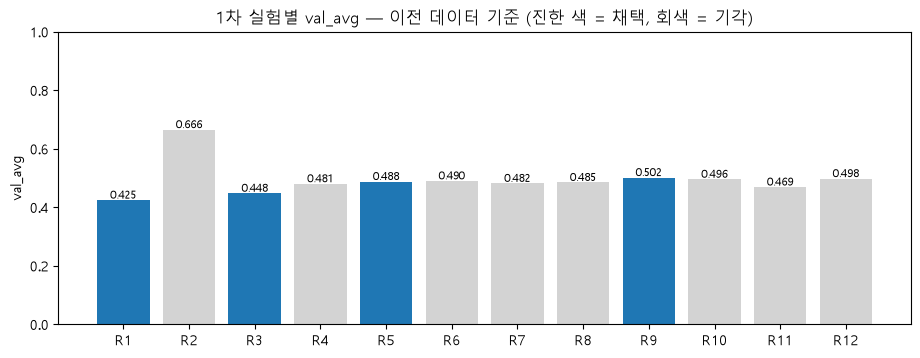

,id,why,val,val_ext,val_hard,val_avg,best_epoch,epochs_run,minutes,adopted,best_after
0,R1,"기준 (Kaggle만, 증강 없음, 128px, 폭 32, 30 epoch)",0.7894,0.144,0.3408,0.4248,17,24,12.65,True,R1
1,R2,외부 데이터 혼합,0.7465,0.772,0.4783,0.6656,17,24,16.44,False,R1
2,R3,어둡게·흐림 증강,0.7890,0.154,0.4017,0.4482,17,24,11.36,True,R3
3,R4,좌우반전·무작위 자르기 추가,0.7963,0.194,0.4517,0.4807,29,30,14.88,False,R3
4,R5,cosine 학습률,0.8032,0.156,0.5058,0.4883,30,30,13.91,True,R5
5,R6,epoch 60,0.8053,0.172,0.4942,0.4905,33,43,20.04,False,R5
6,R7,epoch 100,0.7911,0.178,0.4767,0.4819,48,63,29.30,False,R5
7,R8,MLP 헤드,0.7937,0.180,0.4817,0.4851,26,30,14.01,False,R5
8,R9,모델 폭 48,0.8156,0.184,0.5058,0.5018,22,29,14.11,True,R9
9,R10,입력 160px,0.8315,0.160,0.4967,0.4961,30,30,17.27,False,R9


[2차 — 정리한 데이터 기준] 최종 설정: M8 {'width': 48, 'hidden': [], 'img_size': 128, 'resize': None, 'aug': ['dark_blur', 'hflip', 'vflip', 'rot'], 'train_data': 'mix2', 'class_weight': None, 'label_smoothing': 0.0, 'epochs': 60, 'lr': 0.001, 'weight_decay': 0.0001, 'scheduler': 'cosine'}


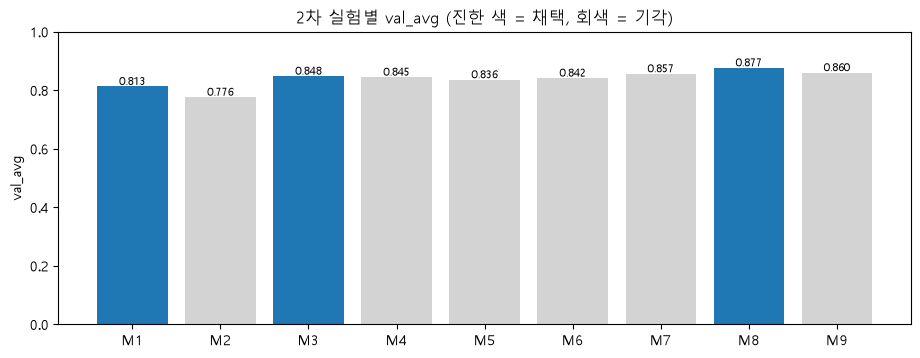

,id,why,val,val_ext,val_hard,val_avg,best_epoch,epochs_run,minutes,adopted,best_after,per_class_delta
0,M1,정리한 혼합 데이터,0.8337,0.8394,0.7663,0.8131,29,30,51.92,True,M1,{}
1,M2,비율 유지(letterbox),0.8496,0.8394,0.6402,0.7764,27,30,48.48,False,M1,"{""battery"": 0.0282, ""biological"": -0.0946, ""br..."
2,M3,"좌우·상하 반전, 회전 증강",0.8590,0.8996,0.7863,0.8483,29,30,47.09,True,M3,"{""battery"": 0.0282, ""biological"": -0.0405, ""br..."
3,M4,밝기·색 변화 증강,0.8556,0.8936,0.7855,0.8449,29,30,65.80,False,M3,"{""battery"": 0.0, ""biological"": -0.0203, ""brown..."
4,M5,무작위 변형 1개를 무작위 세기로 적용(trivial) 증강,0.8376,0.8835,0.7871,0.8361,30,30,49.06,False,M3,"{""battery"": -0.0282, ""biological"": -0.0068, ""b..."
5,M6,클래스 가중치,0.8526,0.8956,0.7771,0.8418,27,30,52.31,False,M3,"{""battery"": 0.0211, ""biological"": -0.0135, ""br..."
6,M7,라벨 스무딩 0.1,0.8689,0.9076,0.7930,0.8565,30,30,45.02,False,M3,"{""battery"": -0.0845, ""biological"": 0.0405, ""br..."
7,M8,epoch 60,0.8792,0.9217,0.8297,0.8769,50,60,98.89,True,M8,"{""battery"": 0.007, ""biological"": 0.0473, ""brow..."
8,M9,입력 160px,0.8853,0.9137,0.7821,0.8604,58,60,106.82,False,M8,"{""battery"": 0.0352, ""biological"": 0.0203, ""bro..."


In [21]:
# [셀 목적] 1차(이전 데이터 기준)·2차 단계별 val·val_ext·val_hard·val_avg 표와 val_avg 막대(채택=진한 색), 2차에서 최종 설정(FINAL_ID) 결정
TABLE_COLS = ["id", "why", "val", "val_ext", "val_hard", "val_avg", "best_epoch", "epochs_run", "minutes", "adopted", "best_after"]


def bar_ladder(df: pd.DataFrame, title: str):
    fig, ax = plt.subplots(figsize=(11, 3.8))
    ax.bar(df.id, df.val_avg, color=["tab:blue" if a else "lightgray" for a in df.adopted])
    for i, v in enumerate(df.val_avg):
        ax.text(i, v + 0.005, f"{v:.3f}", ha="center", fontsize=8)
    ax.set(title=title, ylabel="val_avg", ylim=(0, 1))
    plt.show()


if not ladder_df_r1.empty:
    print("[1차 — 이전 데이터 기준] 정리하기 전 데이터로 학습·검증한 값이라 2차 숫자와 직접 비교하지 않는다")
    bar_ladder(ladder_df_r1, "1차 실험별 val_avg — 이전 데이터 기준 (진한 색 = 채택, 회색 = 기각)")
    display(ladder_df_r1[TABLE_COLS].round(4))

FINAL_ID = None if ladder_df.empty else ladder_df.best_after.iloc[-1]
if FINAL_ID is None:
    print("2차 실험 결과가 없어 최종 설정 이후(10~12절 일부)를 건너뜀")
else:
    FINAL_CFG = json.load(open(EXP_ROOT / FINAL_ID / "cfg.json", encoding="utf-8"))
    print("[2차 — 정리한 데이터 기준] 최종 설정:", FINAL_ID,
          {k: FINAL_CFG.get(k) for k in ["width", "hidden", "img_size", "resize", "aug", "train_data", "class_weight",
                                          "label_smoothing", "epochs", "lr", "weight_decay", "scheduler"]})
    bar_ladder(ladder_df, "2차 실험별 val_avg (진한 색 = 채택, 회색 = 기각)")
    display(ladder_df[TABLE_COLS + ["per_class_delta"]].round(4))

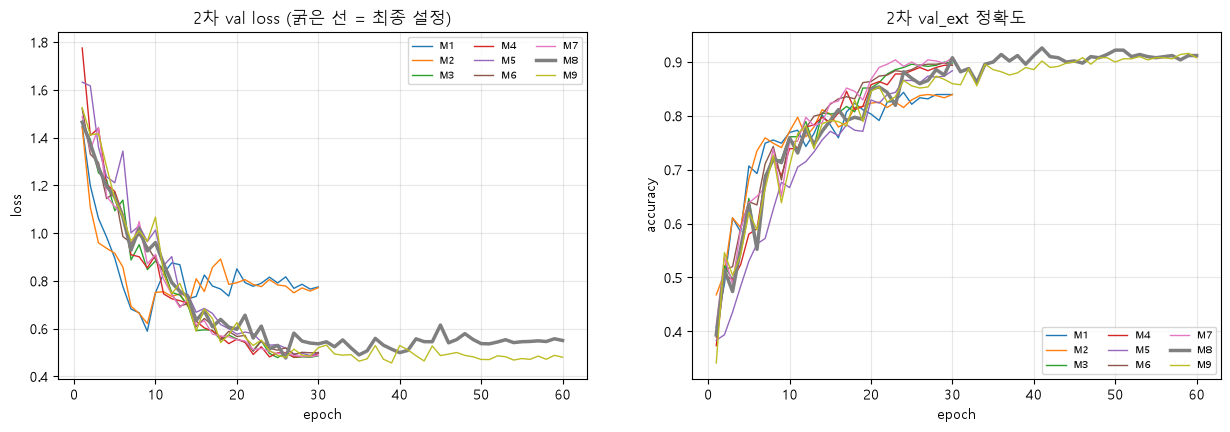

In [22]:
# [셀 목적] 2차 실험별 val loss와 val_ext 정확도 곡선을 겹쳐 그림 — 어떤 변경이 학습 양상을 바꿨는지 비교
if FINAL_ID is not None:
    fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
    for k, e in enumerate(ladder_df.id):
        if not (EXP_ROOT / e / "history.csv").exists():
            continue
        h = pd.read_csv(EXP_ROOT / e / "history.csv")
        lw = 2.5 if e == FINAL_ID else 1
        ax[0].plot(h.epoch, h.val_loss, color=f"C{k % 10}", lw=lw, label=e)
        ax[1].plot(h.epoch, h.val_ext_acc, color=f"C{k % 10}", lw=lw, label=e)
    ax[0].set(title="2차 val loss (굵은 선 = 최종 설정)", xlabel="epoch", ylabel="loss")
    ax[1].set(title="2차 val_ext 정확도", xlabel="epoch", ylabel="accuracy")
    for a in ax:
        a.grid(alpha=0.3)
        a.legend(fontsize=7, ncol=3)
    plt.show()

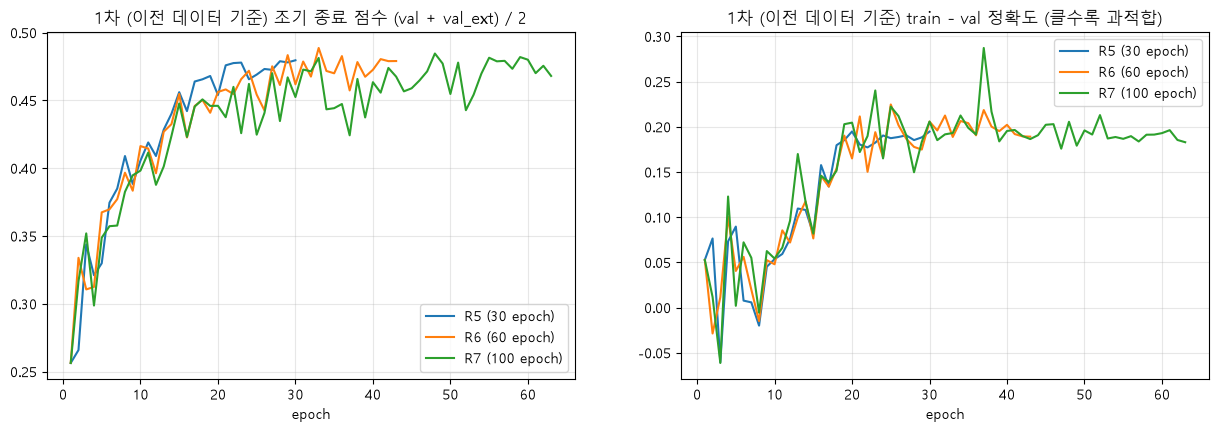

,id,why,val_avg,best_epoch,epochs_run,minutes,adopted
4,R5,cosine 학습률,0.4883,30,30,13.91,True
5,R6,epoch 60,0.4905,33,43,20.04,False
6,R7,epoch 100,0.4819,48,63,29.30,False


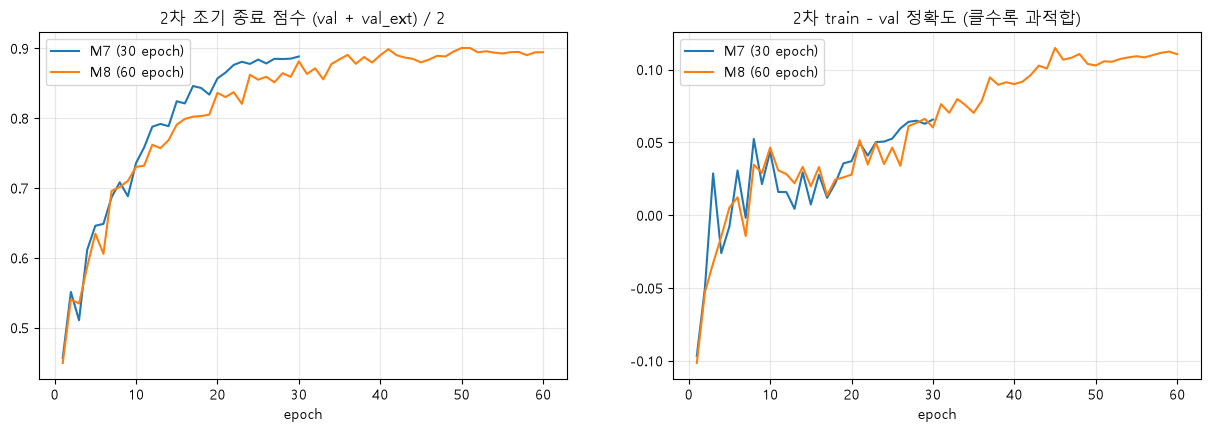

,id,why,val_avg,best_epoch,epochs_run,minutes,adopted
6,M7,라벨 스무딩 0.1,0.8565,30,30,45.02,False
7,M8,epoch 60,0.8769,50,60,98.89,True


In [23]:
# [셀 목적] epoch 증가 효과 — 1차(R5·R6·R7 = 30·60·100 epoch)와 2차(M7·M8 = 30·60 epoch)의 조기 종료 점수와 train-val 정확도 차이(과적합 지표). 있는 것만 그림
for round_name, df, wanted in [("1차 (이전 데이터 기준)", ladder_df_r1, ["R5", "R6", "R7"]), ("2차", ladder_df, ["M7", "M8"])]:
    ids = [e for e in wanted if not df.empty and e in df.id.tolist() and (EXP_ROOT / e / "history.csv").exists()]
    if not ids:
        continue
    fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
    for e in ids:
        h = pd.read_csv(EXP_ROOT / e / "history.csv")
        n = json.load(open(EXP_ROOT / e / "cfg.json", encoding="utf-8"))["epochs"]
        ax[0].plot(h.epoch, h.score, label=f"{e} ({n} epoch)")
        ax[1].plot(h.epoch, h.train_acc - h.val_acc, label=f"{e} ({n} epoch)")
    ax[0].set(title=f"{round_name} 조기 종료 점수 (val + val_ext) / 2", xlabel="epoch")
    ax[1].set(title=f"{round_name} train - val 정확도 (클수록 과적합)", xlabel="epoch")
    for a in ax:
        a.grid(alpha=0.3)
        a.legend()
    plt.show()
    display(df[df.id.isin(ids)][["id", "why", "val_avg", "best_epoch", "epochs_run", "minutes", "adopted"]].round(4))

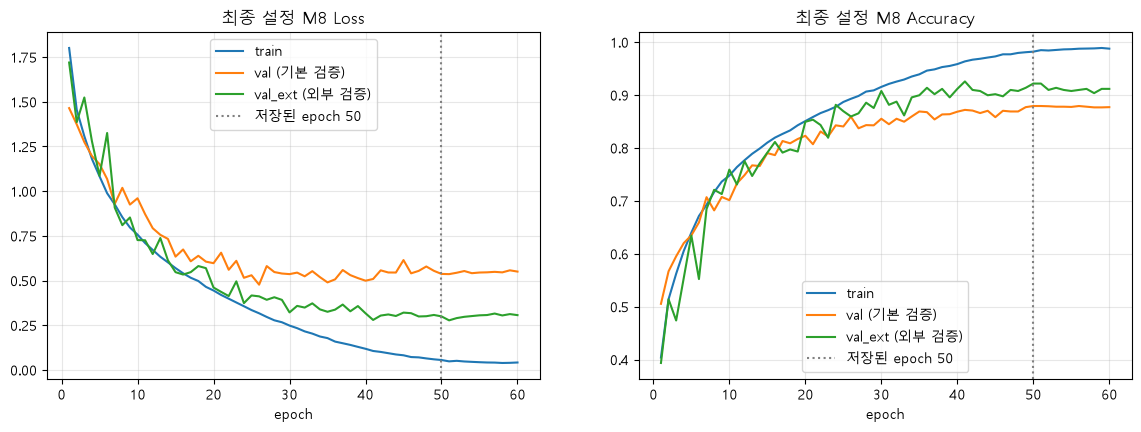

저장된 epoch 50: train acc 0.9820 / val acc 0.8792 → 차이 +0.1028
val loss 최저 epoch = 26 / 실행 epoch = 60


In [24]:
# [셀 목적] 최종 설정의 손실·정확도 곡선(train / val / val_ext)과 과적합 지표 출력
if FINAL_ID is not None:
    history = pd.read_csv(EXP_ROOT / FINAL_ID / "history.csv")
    best_ep = json.load(open(EXP_ROOT / FINAL_ID / "metrics.json", encoding="utf-8"))["best_epoch"]
    fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
    for col, lab in [("train", "train"), ("val", "val (기본 검증)"), ("val_ext", "val_ext (외부 검증)")]:
        ax[0].plot(history.epoch, history[f"{col}_loss"], label=lab)
        ax[1].plot(history.epoch, history[f"{col}_acc"], label=lab)
    for a, t in zip(ax, ["Loss", "Accuracy"]):
        a.axvline(best_ep, color="gray", ls=":", label=f"저장된 epoch {best_ep}")
        a.set(title=f"최종 설정 {FINAL_ID} {t}", xlabel="epoch")
        a.grid(alpha=0.3)
        a.legend()
    plt.show()
    b = history[history.epoch == best_ep].iloc[0]
    print(f"저장된 epoch {best_ep}: train acc {b.train_acc:.4f} / val acc {b.val_acc:.4f} → 차이 {b.train_acc - b.val_acc:+.4f}")
    print(f"val loss 최저 epoch = {int(history.loc[history.val_loss.idxmin(), 'epoch'])} / 실행 epoch = {int(history.epoch.max())}")

In [25]:
# [셀 목적] 혼동행렬 만들기·그리기, 클래스별 정밀도/재현율/F1, 주요 혼동 쌍, TEST를 한 번만 평가하는 함수 정의
def confusion(labels, preds_) -> pd.DataFrame:
    """정답·예측 번호 배열 → 혼동행렬 (행 = 그 셋에 있는 정답 클래스, 열 = 12클래스)"""
    t, p_ = np.array(CLASSES)[labels], np.array(CLASSES)[preds_]
    present = [c for c in CLASSES if c in set(t)]
    return pd.crosstab(pd.Series(t, name="정답"), pd.Series(p_, name="예측")).reindex(index=present, columns=CLASSES, fill_value=0)


def plot_cm(ax, cm: pd.DataFrame, title: str):
    """색 = 정답 행 기준 비율, 숫자 = 장수, 빨간 숫자 = 오답"""
    v = cm.values
    rate = v / np.maximum(v.sum(1, keepdims=True), 1)
    ax.imshow(rate, cmap="Blues", vmin=0, vmax=1, aspect="auto")
    for i in range(v.shape[0]):
        for j in range(v.shape[1]):
            if v[i, j]:
                ax.text(j, i, v[i, j], ha="center", va="center", fontsize=7,
                        color="white" if rate[i, j] > 0.5 else ("crimson" if cm.index[i] != cm.columns[j] else "black"))
    ax.set_xticks(range(v.shape[1]), cm.columns, rotation=60, ha="right", fontsize=8)
    ax.set_yticks(range(v.shape[0]), cm.index, fontsize=8)
    ax.set(title=title, xlabel="예측", ylabel="정답")


def class_report(cm: pd.DataFrame) -> pd.DataFrame:
    """정밀도 = 그 클래스로 예측한 것 중 맞은 비율, 재현율 = 그 클래스 사진 중 맞힌 비율"""
    cm = cm.reindex(columns=sorted(set(cm.columns) | set(cm.index), key=lambda c: CLASSES.index(c) if c in CLASSES else 99), fill_value=0)
    tp = np.array([cm.loc[c, c] for c in cm.index])
    pred_tot = cm[cm.index].sum(axis=0).values
    true_tot = cm.sum(axis=1).values
    prec = np.divide(tp, pred_tot, out=np.full(len(tp), np.nan), where=pred_tot > 0)
    rec = tp / true_tot
    f1 = np.where(prec + rec > 0, 2 * prec * rec / (prec + rec), 0)
    return pd.DataFrame(dict(장수=true_tot, 정밀도=prec, 재현율=rec, F1=f1, 오탐=pred_tot - tp, 미탐=true_tot - tp),
                        index=cm.index).round(3)


def top_confusions(cm: pd.DataFrame, k: int = 6) -> pd.DataFrame:
    s = cm.stack()
    s = s[[a != b for a, b in s.index]]
    s = s[s > 0].sort_values(ascending=False).head(k)
    return pd.DataFrame({"정답 → 예측": [f"{a} → {b}" for a, b in s.index], "장수": s.values})


def final_test_once(model, test_sets: dict, out_dir: Path, img_size: int = 128, mode: str = "squash") -> dict:
    """TEST 평가는 한 번만: out_dir/final_test.json이 있으면 중단. 없으면 평가 후 정확도 json과 혼동행렬 CSV 저장.
    mode는 최종 설정의 크기 맞추기 방식(squash/letterbox) — 학습 때와 같아야 한다"""
    out_dir = Path(out_dir)
    assert not (out_dir / "final_test.json").exists(), "TEST는 이미 1회 평가함 — 다시 평가하지 않는다"
    out_dir.mkdir(parents=True, exist_ok=True)
    _, eval_tf = build_transforms(img_size, [])
    res = {}
    for k, df in test_sets.items():
        d = cache_resized(df, CACHE_ROOT, name=k, mode=mode).reset_index(drop=True)
        _, acc, p, y = evaluate(model.to(DEVICE).eval(), make_loader(d, eval_tf, 128, False), nn.CrossEntropyLoss())
        res[k] = {"acc": round(acc, 4), "n": len(d)}
        confusion(y, p).to_csv(out_dir / f"final_{k}_confusion.csv", encoding="utf-8-sig")
    json.dump(res, open(out_dir / "final_test.json", "w", encoding="utf-8"), ensure_ascii=False, indent=1)
    print("TEST 1회 평가 완료:", res)
    return res

### 2차 결과 해석 (M1~M9)
| 단계 | 바꾼 것 | val | val_ext | val_hard | val_avg | 판정 |
|---|---|---|---|---|---|---|
| M1 | 정리한 혼합 데이터 | 0.834 | 0.839 | 0.766 | 0.813 | 채택 |
| M2 | 비율 유지(letterbox) | 0.850 | 0.839 | 0.640 | 0.776 | 기각 |
| M3 | 좌우·상하 반전, 회전 | 0.859 | 0.900 | 0.786 | 0.848 | 채택 |
| M4 | 밝기·색 변화 | 0.856 | 0.894 | 0.785 | 0.845 | 기각 |
| M5 | TrivialAugmentWide | 0.838 | 0.884 | 0.787 | 0.836 | 기각 |
| M6 | 클래스 가중치 | 0.853 | 0.896 | 0.777 | 0.842 | 기각 |
| M7 | 라벨 스무딩 0.1 | 0.869 | 0.908 | 0.793 | 0.857 | 기각 (+0.008) |
| **M8** | **epoch 60** | 0.879 | 0.922 | 0.830 | **0.877** | **채택 → 최종** |
| M9 | 입력 160px | 0.885 | 0.914 | 0.782 | 0.860 | 기각 |

- **데이터 정리가 가장 큰 효과였다.** 1차 최고(R9)의 val_ext는 0.184였는데, 정리한 혼합 데이터(M1)만으로 0.839가 되었다. 1차의 낮은 val_ext는 모델이 아니라 학습 데이터에 외부 사진이 없었던 탓이다.
- **반전·회전 증강(M3)** 이 그다음으로 컸다(+0.035). 쓰레기 사진은 놓인 방향이 제각각이라 잘 맞는다. 여기에 색 변화(M4)나 TrivialAugmentWide(M5)를 더하면 오히려 조금 떨어졌다.
- **비율 유지(M2)** 는 val_hard를 크게 떨어뜨렸다(0.766 → 0.640). 흐리거나 어두운 사진에서 평균색 여백이 방해가 된 것으로 보여 쓰지 않았다.
- **epoch 60(M8)** 은 세 지표를 모두 올렸다. 30 epoch 실험(M3·M7)은 마지막 epoch까지 점수가 오르고 있었다(학습 부족). M8은 epoch 50에서 가장 좋았고, 특히 손상 사진(val_hard +0.043)이 좋아졌다.
- **입력 160px(M9)** 은 val만 올리고 val_hard를 떨어뜨렸다. 흐림 사진 정확도가 0.812 → 0.687로 떨어졌다.

**과적합 점검 (M8)**
- 저장한 epoch 50에서 train 정확도 0.982, val 0.879로 차이가 약 0.10이다. val loss는 epoch 26(0.477)에서 가장 낮았고 그 뒤로 조금씩 올랐다(epoch 50에서 0.537).
- 그래도 val 정확도는 떨어지지 않고 0.87~0.88을 유지했다. loss가 오른 것은 틀린 사진을 지나치게 확신하게 되었다는 뜻이고, 맞히는 비율은 그대로다. 그래서 가벼운 과적합으로 보고, val이 가장 좋은 epoch의 가중치를 쓴다.

**한계**
- 채택 여부와 최고 epoch를 모두 같은 검증셋으로 골랐으므로 검증 점수는 조금 낙관적이다. 진짜 성능은 12절 TEST로 확인한다.
- seed 하나로 실험했고 val_ext는 498장이라, 0.92 근처에서 우연에 의한 차이가 약 ±0.012다. M8의 향상(+0.029)은 이보다 크지만, M4·M6·M7처럼 차이가 0.01 안쪽인 단계는 효과가 없다기보다 **뚜렷한 효과를 확인하지 못한 것**이다.
- 배경 점검: AI Hub 금속 사진을 battery·유리로 예측한 비율이 M3 0.04에서 M8 0.12로 늘었다. 다만 AI Hub 금속은 25장뿐이라 1장 → 3장의 차이로, 우연일 수도 있다. 지켜볼 신호로만 적어 둔다.
- val에서 white-glass(0.67)·battery(0.78)·plastic(0.78)·shoes(0.81)가 약하다. val_ext에는 clothes·shoes가 없어 두 클래스의 외부 사진 성능은 재지 못했다.

## 11. 최종 모델 검증 평가 — val / val_ext / val_hard / val_avg
최종 설정의 저장된 가중치(최고 epoch)로 세 검증셋을 다시 평가한다. 크기 맞추기 방식(찌그러뜨림/비율 유지)도 최종 설정과 같게 맞춘다.

| 지표 | 데이터 | 의미 |
|---|---|---|
| **val** | Kaggle 원본 검증 2,327장 | 깨끗한 사진에서의 정확도 |
| **val_ext** | 외부 실사 사진 498장 (RealWaste·AI Hub, clothes·shoes 없음) | 다른 촬영 환경·배경에서의 정확도 |
| **val_hard** | 손상 사진 1,198장 (흐림·어둡게·빛번짐) | 어둡거나 흐린 사진에서의 정확도 |
| **val_avg** | (val + val_ext + val_hard) / 3 | 세 검증 지표의 평균. 모델 선택 기준 |

### 배경 점검: AI Hub 금속 사진
AI Hub 사진은 아스팔트 같은 바닥 위에서 찍은 것이 많다. 그래서 모델이 물건이 아니라 **배경을 보고 답을 외웠을** 수 있다(배경 외우기).
이를 알아보려고 val_ext의 출처별(RealWaste / AI Hub) 정확도를 나누어 보고, AI Hub 금속(metal) 사진을 모델이 무엇으로 예측했는지 센다.
금속이 battery나 유리(brown-glass·green-glass·white-glass)로 많이 예측되면, 물건 대신 배경(아스팔트)을 단서로 쓰고 있다는 신호이다.

,장수,loss,accuracy
검증셋,,,
val,2327.0,0.5371,0.8792
val_ext,498.0,0.2997,0.9217
val_hard,1198.0,0.6522,0.8297
val_avg (세 지표 평균),NaN,NaN,0.8769


,val,val_ext,val_hard
battery,0.782,0.980,0.750
biological,0.919,1.000,0.869
brown-glass,0.934,0.980,0.890
cardboard,0.872,0.900,0.810
clothes,0.937,NaN,0.940
green-glass,0.968,1.000,0.980
metal,0.845,0.840,0.830
paper,0.943,0.860,0.830
plastic,0.783,0.900,0.890
shoes,0.814,NaN,0.690


,정확도,장수
corruption,,
blur,0.8120,399
dark,0.8020,404
glare,0.8759,395


val_ext 출처별 정확도 (출처마다 사진 환경이 다르다)


,정확도,장수
source,,
aihub,0.9511,225
realwaste,0.8974,273


AI Hub 금속 사진 25장 중 battery·유리로 예측한 비율: 0.120 (높을수록 배경 외우기 의심)


,장수,비율
예측 클래스,,
metal,20,0.80
trash,1,0.04
plastic,1,0.04
green-glass,1,0.04
white-glass,1,0.04
brown-glass,1,0.04


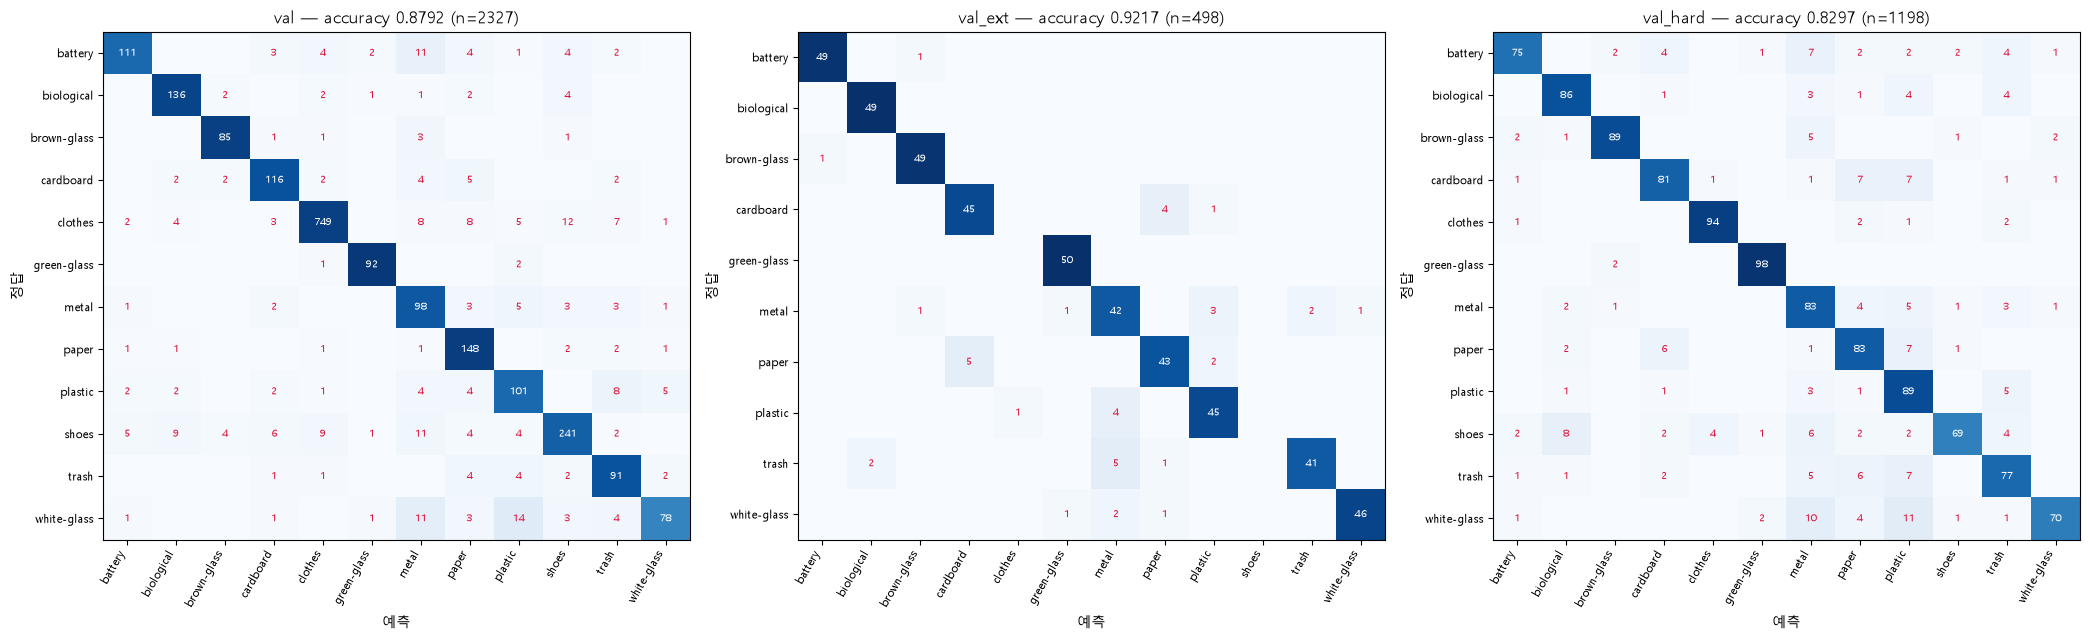

In [26]:
# [셀 목적] 최종 가중치를 불러와 val / val_ext / val_hard 평가 → 점수표(val_avg 포함), 클래스별·손상별 정확도, val_ext 출처별 정확도와 AI Hub metal 예측 분포(배경 점검), 혼동행렬
aihub_metal_as_glass_battery, source_acc, metal_pred = None, pd.DataFrame(), pd.DataFrame()
if FINAL_ID is not None:
    w = EXP_ROOT / FINAL_ID / "best.pth"
    if not w.exists():   # 다른 모델 가중치로 조용히 대체하지 않는다
        raise FileNotFoundError(f"최종 실험 {FINAL_ID}의 가중치가 없음: {w} → Drive의 experiments/ 폴더 전체를 가져와 RESULT/experiments/에 두세요")
    final_model = build_model(FINAL_CFG)
    final_model.load_state_dict(torch.load(w, map_location="cpu"))
    final_model = final_model.to(DEVICE).eval()
    _, eval_tf = build_transforms(FINAL_CFG["img_size"], [])
    criterion = nn.CrossEntropyLoss()
    preds, rows = {}, []
    for k, df in {"val": val_df, "val_ext": val_ext, "val_hard": val_hard}.items():
        d = cache_resized(df, CACHE_ROOT, name=k, mode=FINAL_CFG.get("resize", "squash")).reset_index(drop=True)
        loss, acc, p, y = evaluate(final_model, make_loader(d, eval_tf, 128, False), criterion)
        preds[k] = (d, p, y)
        rows.append({"검증셋": k, "장수": len(d), "loss": round(loss, 4), "accuracy": round(acc, 4)})
    scores = pd.DataFrame(rows).set_index("검증셋")
    scores.loc["val_avg (세 지표 평균)", "accuracy"] = round(scores.accuracy.mean(), 4)
    display(scores)
    per_class = pd.DataFrame({k: pd.Series({c: (p[y == i] == i).mean() if (y == i).any() else np.nan for i, c in enumerate(CLASSES)})
                              for k, (_, p, y) in preds.items()}).round(3)
    display(per_class)
    d, p, y = preds["val_hard"]
    display(d.assign(ok=(p == y)).groupby("corruption").ok.agg(정확도="mean", 장수="size").round(4))

    # 배경 점검 1) val_ext 출처별 정확도
    d, p, y = preds["val_ext"]
    source_acc = d.assign(ok=(p == y)).groupby("source").ok.agg(정확도="mean", 장수="size").round(4)
    print("val_ext 출처별 정확도 (출처마다 사진 환경이 다르다)")
    display(source_acc)
    # 배경 점검 2) AI Hub 금속 사진을 무엇으로 예측했나
    metal = ((d.source == "aihub") & (d.label == "metal")).to_numpy()
    if metal.any():
        pred_names = pd.Series(np.array(CLASSES)[p[metal]])
        metal_pred = pred_names.value_counts().rename_axis("예측 클래스").to_frame("장수")
        metal_pred["비율"] = (metal_pred["장수"] / metal.sum()).round(3)
        aihub_metal_as_glass_battery = float(pred_names.isin(["battery", "brown-glass", "green-glass", "white-glass"]).mean())
        print(f"AI Hub 금속 사진 {int(metal.sum())}장 중 battery·유리로 예측한 비율: {aihub_metal_as_glass_battery:.3f}"
              " (높을수록 배경 외우기 의심)")
        display(metal_pred)
    else:
        print("val_ext에 AI Hub 금속 사진이 없어 배경 점검을 건너뜀")
    fig, ax = plt.subplots(1, 3, figsize=(21, 6.5))
    for a, (k, (_, p, y)) in zip(ax, preds.items()):
        plot_cm(a, confusion(y, p), f"{k} — accuracy {(p == y).mean():.4f} (n={len(y)})")
    plt.tight_layout()
    plt.show()

## 12. 최종 TEST (1회)
| 지표 | 데이터 | 의미 |
|---|---|---|
| **test** | Kaggle 원본 테스트 2,328장 (12클래스) | 깨끗한 사진에서의 최종 정확도 |
| **test_ext** | 외부 실사 사진 360장 (9클래스, biological·clothes·shoes 없음) | 다른 촬영 환경에서의 최종 정확도 |

test_ext는 정리한 뒤의 360장(RealWaste 180·AI Hub 180)이다.

TEST는 실험과 모델 선택이 모두 끝난 뒤 **최종 모델로 한 번만** 평가한다. `RUN_FINAL_TEST = True`로 한 번 실행하면 결과가 `RESULT/final_test/`에 저장된다. 그 뒤로는 저장된 결과를 읽기만 하고, 다시 평가하려 하면 막는다.

,장수,accuracy
test,2328.0,0.8823
test_ext,360.0,0.9028


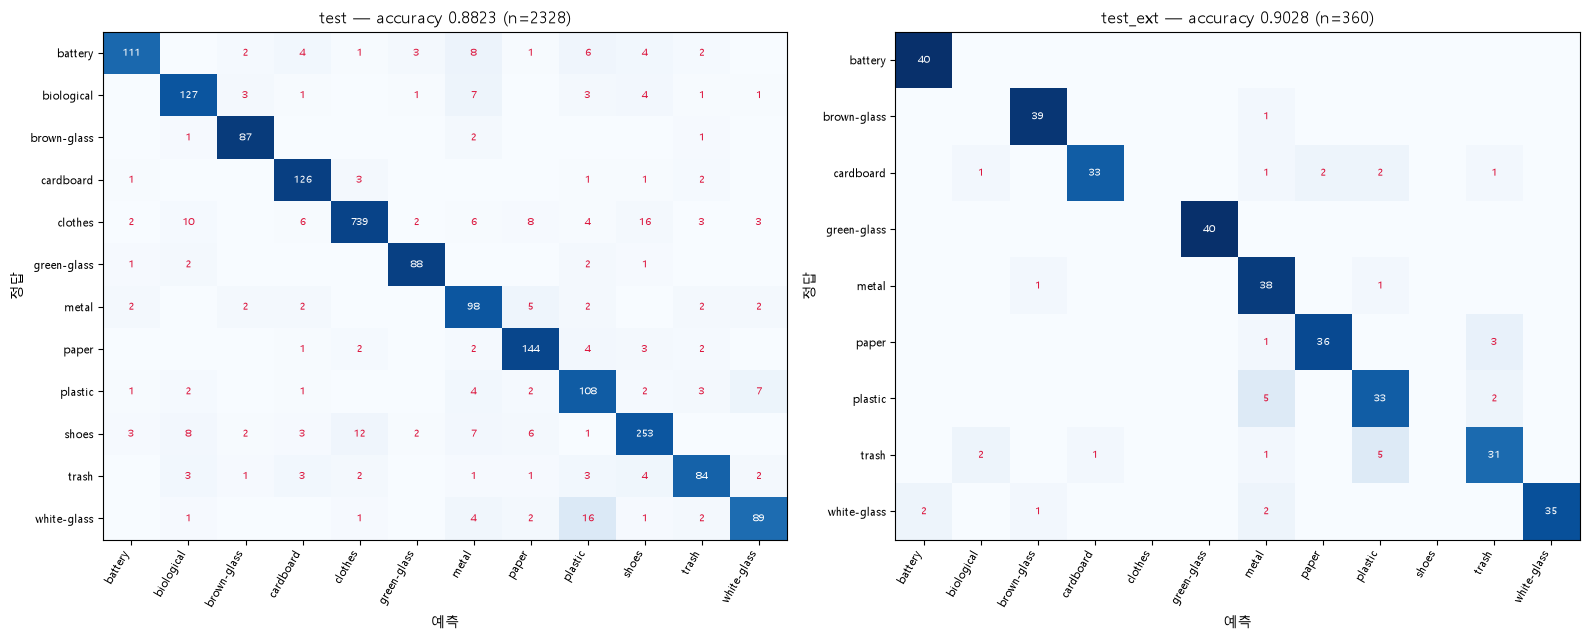

test                              test_ext                                
              장수    정밀도    재현율     F1  오탐  미탐       장수    정밀도    재현율     F1    오탐   미탐
정답                                                                                    
battery      142  0.917  0.782  0.844  10  31     40.0  0.952  1.000  0.976   2.0  0.0
biological   148  0.825  0.858  0.841  27  21      NaN    NaN    NaN    NaN   NaN  NaN
brown-glass   91  0.897  0.956  0.926  10   4     40.0  0.951  0.975  0.963   2.0  1.0
cardboard    134  0.857  0.940  0.897  21   8     40.0  0.971  0.825  0.892   1.0  7.0
clothes      799  0.972  0.925  0.948  21  60      NaN    NaN    NaN    NaN   NaN  NaN
green-glass   94  0.917  0.936  0.926   8   6     40.0  1.000  1.000  1.000   0.0  0.0
metal        115  0.705  0.852  0.772  41  17     40.0  0.776  0.950  0.854  11.0  2.0
paper        158  0.852  0.911  0.881  25  14     40.0  0.947  0.900  0.923   2.0  4.0
plastic      130  0.720  0.831  0.771  42  22     40.0  0.805  0.825  0.815   8.0  7.0
shoes        297  0.875  0.852  0.863  36  44      NaN    NaN    NaN    NaN   NaN  NaN
trash        104  0.824  0.808  0.816  18  20     40.0  0.838  0.775  0.805   6.0  9.0
white-glass  116  0.856  0.767  0.809  15  27     40.0  1.000  0.875  0.933   0.0  5.0

test                   test_ext   
                 정답 → 예측  장수                정답 → 예측 장수
0        clothes → shoes  16        plastic → metal  5
1  white-glass → plastic  16        trash → plastic  5
2        shoes → clothes  12          paper → trash  3
3   clothes → biological  10    white-glass → metal  2
4        battery → metal   8  white-glass → battery  2
5     shoes → biological   8        plastic → trash  2

In [27]:
# [셀 목적] RUN_FINAL_TEST=True면 TEST 1회 평가·저장(이미 있으면 중단), 이후 저장된 결과로 정확도 표·혼동행렬·클래스별 정밀도/재현율·주요 혼동 쌍
if FINAL_ID is not None and RUN_FINAL_TEST:
    final_test_once(final_model, {"test": test_df, "test_ext": test_ext}, FINAL_DIR, img_size=FINAL_CFG["img_size"],
                    mode=FINAL_CFG.get("resize", "squash"))
if (FINAL_DIR / "final_test.json").exists():
    final = json.load(open(FINAL_DIR / "final_test.json", encoding="utf-8"))
    test_cm = {k: pd.read_csv(FINAL_DIR / f"final_{k}_confusion.csv", index_col=0) for k in ["test", "test_ext"]}
    display(pd.DataFrame({k: {"장수": final[k]["n"], "accuracy": final[k]["acc"]} for k in test_cm}).T)
    fig, ax = plt.subplots(1, 2, figsize=(16, 6.5))
    for a, (k, cm) in zip(ax, test_cm.items()):
        plot_cm(a, cm, f"{k} — accuracy {final[k]['acc']:.4f} (n={final[k]['n']})")
    plt.tight_layout()
    plt.show()
    display(pd.concat({k: class_report(cm) for k, cm in test_cm.items()}, axis=1))
    display(pd.concat({k: top_confusions(cm) for k, cm in test_cm.items()}, axis=1))
else:
    print("아직 TEST를 평가하지 않음 (사다리 완료 후 RUN_FINAL_TEST=True로 한 번 실행)")

## 12-2. 더러운 사진 추가 평가 (1회)
실제 시연은 지저분하거나 잡음이 섞인 사진으로 할 예정이라, 그런 조건에서 최종 모델을 한 번 더 평가한다. 최종 모델(M8)은 바꾸지 않고, 이 결과를 보고 모델을 다시 고르지 않는다.

**이 평가셋은 학습에 쓴 것과 같은 종류의 물체만 쓴다.** 어려움은 물체가 낯선 데서가 아니라 사진이 더럽거나 잡음이 있다는 데서만 온다. (이전에 만든 평가셋은 학습에 없던 종류의 물체 — 잎·풀, 커피 찌꺼기, 옷 더미·매장 진열, 과자 봉지·휴지 — 를 넣어 평가 목적에서 벗어났기 때문에 사용자 지시로 폐기하고 다시 만들었다. 그 결과 0.753은 쓰지 않는다.)

| 항목 | 내용 |
|---|---|
| 장수 | 1,200장 = 12클래스 × 100장 |
| Kaggle : 외부 | 599 : 601 (50 : 50). 클래스마다 Kaggle test 40장 + 외부 60장이 목표이고, 같은 종류의 외부 사진이 모자란 클래스는 Kaggle test로 채웠다 |
| 외부 장수(클래스별) | battery·brown-glass·metal·shoes·cardboard·biological 60, green-glass 46, white-glass 60, plastic 60, trash 59, paper 16, clothes 0 |
| 외부 출처 | AI Hub(battery·유리 3색·metal), RealWaste(plastic 40), TriCascade(cardboard·biological), Household(white-glass 투명 유리 단지·병 30, plastic 용기 20, trash 스티로폼 57, paper 신문 16), TrashBusters(trash 마스크·칫솔 2), ShoeSandalBoot(shoes) |
| 손상 | 묶음(클래스 × Kaggle/외부)마다 절반은 원본, 절반은 손상. 학습에 없던 잡음·JPEG 압축·흔들림·저조도+잡음·빛번짐·얼룩과, 학습에 있던 어둡게·흐림을 약·강 두 세기로 |

- 외부 사진은 학습·검증·테스트 사진과 사진 해시로 비교해 같은 사진을 뺐고, 사진을 직접 보며 학습한 종류가 아니거나 라벨이 틀린 사진을 뺐다(`tools/test_dirty_review.json`).
- clothes는 학습한 종류(옷 한 벌)의 외부 사진이 없어 100장 모두 Kaggle test이고, paper는 외부가 16장뿐이라 나머지 84장이 Kaggle test다.
- **주의**: AI Hub 사진은 라벨에 물건 번호가 없어, 같은 물건을 다른 날 찍은 사진이 학습에 있을 수 있다. 그래서 결과를 출처별로 나눠 본다.
- 만드는 코드는 기록용으로 `01_coding/tools/build_test_dirty.py`에 있다(원본 zip이 있어야 실행됨). 노트북은 만들어진 `test_dirty.csv`와 이미지만 읽는다.


전체 정확도 0.7733 (n=1200) | 클래스별 정확도 평균 0.7733


정확도   장수
원본/손상     손상        0.7205  601
          원본        0.8264  599
Kaggle/외부 external  0.7421  601
          kaggle    0.8047  599

정확도   장수
group    corruption             
external 손상          0.6777  301
         원본          0.8067  300
kaggle   손상          0.7633  300
         원본          0.8462  299

정확도   장수
corruption      severity             
blur            mild      0.7955   44
                strong    0.6486   37
dark            mild      0.7907   43
                strong    0.8649   37
glare           mild      0.6136   44
                strong    0.2759   29
jpeg            mild      0.7778   36
                strong    0.7500   36
low_light_noise mild      0.7297   37
                strong    0.5135   37
motion_blur     mild      0.7838   37
                strong    0.7568   37
noise           mild      0.8889   36
                strong    0.6486   37
none            none      0.8264  599
stain           mild      0.9318   44
                strong    0.6000   30

,정확도,장수
source,,
aihub,0.8008,256
hf_shoes,0.9167,60
household_default,0.5088,57
household_real,0.6970,66
realwaste,0.8250,40
tb_trash,1.0000,2
tricascade,0.6333,120


group,external,kaggle
label,,
battery,0.967,0.650
biological,0.467,0.925
brown-glass,0.783,0.900
cardboard,0.800,0.925
clothes,NaN,0.860
green-glass,0.804,0.833
metal,0.650,0.750
paper,0.438,0.810
plastic,0.783,0.750


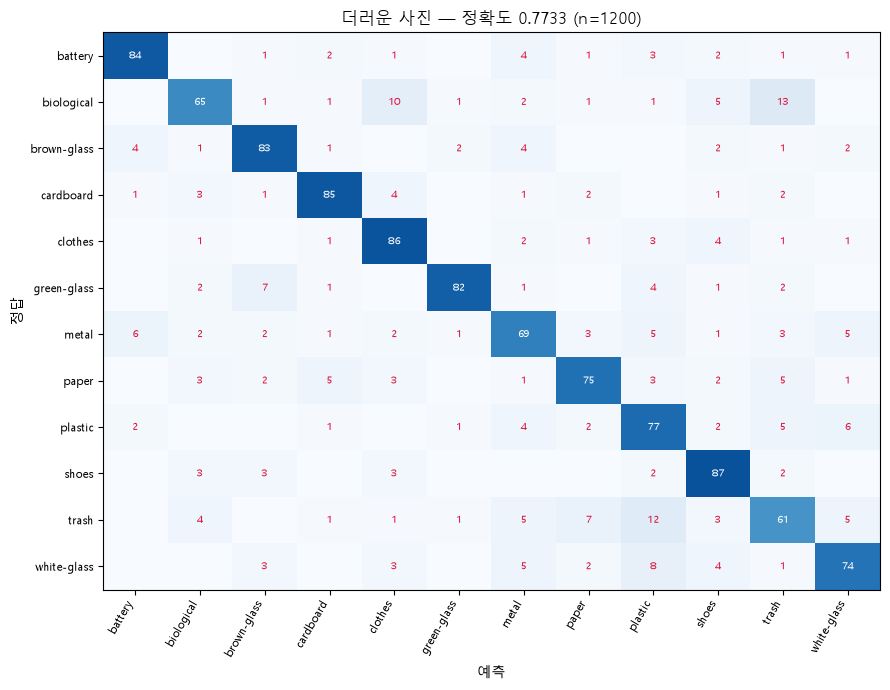

,정답 → 예측,장수
0,biological → trash,13
1,trash → plastic,12
2,biological → clothes,10
3,white-glass → plastic,8
4,trash → paper,7
5,green-glass → brown-glass,7


In [28]:
# [셀 목적] RUN_DIRTY_TEST=True면 최종 모델로 더러운 사진 1,200장을 한 번만 평가·저장(이미 있으면 중단), 이후 저장된 결과로 묶음별 정확도
DIRTY_CSV = DATA_DIR / "test_dirty.csv"


def dirty_test_once(model, df: pd.DataFrame, out_dir: Path, img_size: int = 128, mode: str = "squash") -> pd.DataFrame:
    """더러운 사진 평가는 한 번만: out_dir/dirty_test_predictions.csv가 있으면 중단. 사진마다 예측을 저장한다"""
    out_dir = Path(out_dir)
    f = out_dir / "dirty_test_predictions.csv"
    assert not f.exists(), "더러운 사진 평가는 이미 1회 함 — 다시 평가하지 않는다"
    out_dir.mkdir(parents=True, exist_ok=True)
    _, eval_tf = build_transforms(img_size, [])
    d = cache_resized(df, CACHE_ROOT, name="test_dirty", mode=mode).reset_index(drop=True)
    _, acc, p, y = evaluate(model.to(DEVICE).eval(), make_loader(d, eval_tf, 128, False), nn.CrossEntropyLoss())
    out = d.drop(columns="file").assign(pred=np.array(CLASSES)[p], ok=(p == y))
    out.to_csv(f, index=False, encoding="utf-8")
    print(f"더러운 사진 1회 평가 완료: 정확도 {acc:.4f} (n={len(out)})")
    return out


if FINAL_ID is not None and RUN_DIRTY_TEST:
    assert DIRTY_CSV.exists(), f"더러운 사진 목록이 없음: {DIRTY_CSV} (Drive의 test_dirty.zip 필요)"
    dirty_test_once(final_model, pd.read_csv(DIRTY_CSV), FINAL_DIR, img_size=FINAL_CFG["img_size"],
                    mode=FINAL_CFG.get("resize", "squash"))
if (FINAL_DIR / "dirty_test_predictions.csv").exists():
    dirty = pd.read_csv(FINAL_DIR / "dirty_test_predictions.csv")
    acc = lambda g: g.ok.agg(정확도="mean", 장수="size").round(4)
    print(f"전체 정확도 {dirty.ok.mean():.4f} (n={len(dirty)}) | 클래스별 정확도 평균 {dirty.groupby('label').ok.mean().mean():.4f}")
    display(pd.concat({"원본/손상": dirty.assign(k=np.where(dirty.corruption == 'none', '원본', '손상')).groupby('k').pipe(acc),
                       "Kaggle/외부": dirty.groupby('group').pipe(acc)}))
    display(dirty.groupby(['group', dirty.corruption.ne('none').map({False: '원본', True: '손상'})]).pipe(acc))
    display(dirty.groupby(['corruption', 'severity']).pipe(acc))
    display(dirty[dirty.group == 'external'].groupby('source').pipe(acc))
    display(dirty.pivot_table(index='label', columns='group', values='ok', aggfunc='mean').round(3))
    cm = confusion(dirty.label.map(CLASSES.index).to_numpy(), dirty.pred.map(CLASSES.index).to_numpy())
    fig, ax = plt.subplots(figsize=(9, 7))
    plot_cm(ax, cm, f"더러운 사진 — 정확도 {dirty.ok.mean():.4f} (n={len(dirty)})")
    plt.tight_layout()
    plt.show()
    display(top_confusions(cm))
else:
    print("아직 더러운 사진 평가를 하지 않음 (RUN_DIRTY_TEST=True로 한 번 실행)")

## 13. 결론
**최종 모델**: 직접 구현한 작은 ResNet(폭 48, 파라미터 약 280만 개, 사전학습 없음), 128px 입력, 정리한 혼합 데이터 27,050장, 증강(어둡게·흐림, 좌우·상하 반전, 회전), cosine 학습률, 60 epoch 중 epoch 50의 가중치 (2차 M8).

| 지표 | 장수 | 정확도 |
|---|---|---|
| val | 2,327 | 0.879 |
| val_ext | 498 | 0.922 |
| val_hard | 1,198 | 0.830 |
| **test** (Kaggle 원본, 12클래스) | 2,328 | **0.882** |
| **test_ext** (외부 실사, 9클래스) | 360 | **0.903** |

- **검증과 TEST가 비슷하다.** test 0.882는 val 0.879와 거의 같고, test_ext 0.903은 val_ext 0.922보다 0.019 낮다. 같은 검증셋으로 여러 번 골라서 생긴 낙관이 조금 있지만 크지 않다. 검증셋에 맞춰 과적합된 모델은 아니다.
- **clothes가 많아 test가 부풀려졌는지**: test의 34%가 clothes(799장)다. 클래스별 재현율을 똑같이 평균하면 0.868로, 전체 정확도 0.882와 큰 차이가 없다.
- **잘 맞히는 클래스**: 유리 3색 중 brown·green(test 재현율 0.94~0.96, test_ext 0.98~1.00), cardboard(test 0.94), clothes(test 0.93).
- **약한 클래스와 주요 혼동**
  - white-glass(test 재현율 0.77): 16장을 plastic으로 예측 — 투명한 유리와 투명 플라스틱을 헷갈린다.
  - battery(test 0.78): metal로 8장 — 금속 외형이 비슷하다.
  - clothes ↔ shoes(16장·12장): 옷과 신발이 함께 찍힌 사진이 있다.
  - trash(test_ext 0.78): plastic으로 5장 — 스티로폼 용기와 플라스틱 용기가 비슷하다.
  - metal은 재현율은 높지만 정밀도가 낮다(test 0.71, test_ext 0.78). 다른 클래스(plastic·battery·shoes)를 metal로 예측하는 일이 많다.
- **출처별 차이**: test_ext에서 AI Hub 클래스(battery·유리 3색)는 거의 다 맞혔고(metal 제외 160장 중 154장), RealWaste 클래스(cardboard·paper·plastic·trash)는 160장 중 133장(0.83)이다. 배경이 다양하고 지저분한 실사 사진이 아직 어렵다.

**더러운 사진 추가 평가 (12-2절, 학습한 종류의 물체만 1,200장, 1회)**: 정확도 **0.773** (클래스 평균도 0.773) — TEST(0.882)보다 11%p 낮다.
- **같은 사진 집단에서 원본 대비 손상의 하락폭**이 핵심이다. 전체 원본 0.826 → 손상 0.720(-10.6%p). Kaggle 0.846 → 0.763(-8.3%p), 외부 0.807 → 0.678(-12.9%p). 외부 사진이 손상에 더 약하다. 다만 외부 묶음은 클래스 구성이 다르다(clothes 0장, paper 16장, trash는 대부분 스티로폼). 그래서 이 차이를 출처 때문이라고 단정하기는 어렵다.
- 손상 종류별(약 → 강): 강한 **빛번짐 0.28**(강 29장, 약 0.61), 강한 **저조도+잡음 0.51**(약 0.73), 강한 **얼룩 0.60**(강 30장, 약 0.93), 강한 잡음 0.65(약 0.89), 강한 흐림 0.65(약 0.80)에 크게 약하다. 학습에 있던 어둡게(0.79~0.87)와 흔들림(0.76~0.78), JPEG(0.75~0.78)는 비교적 버틴다. 손상 사진 전체는 0.720이고, 세기별로는 약 0.79 / 강 0.64이다.
- 외부 출처별(원본 → 손상): ShoeSandalBoot 0.97 → 0.87, AI Hub 0.85 → 0.75, RealWaste 1.00 → 0.67, TriCascade(cardboard·biological) 0.73 → 0.53.
- 약한 클래스(원본 → 손상): trash 0.76 → 0.47(그중 외부 trash 59장, 대부분 스티로폼: 0.66 → 0.40), biological 0.72 → 0.58(외부 음식 사진 0.60 → 0.33), metal 0.78 → 0.60. 손상에 크게 흔들리는 쪽은 trash와 biological이다.
- 주요 오답: biological → trash(13)·clothes(10), trash → plastic(12)·paper(7), white-glass → plastic(8), green-glass → brown-glass(7), metal → battery(6).
- 정리: 학습한 종류의 물체라도 **강한 빛번짐·저조도+잡음처럼 학습에 없던 손상**이 강하면 성능이 크게 떨어진다. 같은 사진 집단에서 원본과 손상의 차이가 약 10%p이므로, 시연 사진이 이런 손상을 포함하면 0.7대 초반까지 내려갈 수 있다(이 평가셋의 손상 종류·세기 구성 기준). 다만 이 평가셋으로 모델을 고르거나 다시 학습하지는 않았다.

**과정에서 배운 점**
1. 성능을 가장 많이 올린 것은 모델 구조가 아니라 **데이터**였다. 외부 실사 사진을 섞고 라벨이 맞지 않는 사진을 걸러내자 val_ext가 0.18에서 0.84로 올랐다.
2. 증강은 방향을 바꾸는 것(반전·회전)이 효과가 있었고, 색 변화나 강한 무작위 변형은 더해도 이득이 없었다.
3. 30 epoch은 부족했다. 60 epoch에서 세 검증 지표가 모두 올랐고, 과적합은 가벼웠다(train−val 정확도 차이 0.10, val 정확도 유지).

**한계**
- test_ext에는 biological·clothes·shoes가 없어 이 세 클래스의 외부 사진 성능은 재지 못했다.
- seed 하나로 실험해, 차이가 0.01 안쪽인 비교는 우연일 수 있다.
- AI Hub 금속 사진 25장 중 3장을 battery·유리로 예측했다. 배경을 단서로 쓰는 경향이 조금 남아 있을 수 있다.
- TEST는 최종 모델로 한 번만 평가했다. 이 결과를 보고 모델을 다시 고르지 않았다.